# Progetto Machine Learning - 737664

## Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, PolynomialFeatures, RobustScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# StratifiedKFold per diversi training e test set
from sklearn.model_selection import StratifiedKFold

# Tree-based models
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import ExtraTreesClassifier

# Linear models
from sklearn.linear_model import LogisticRegression

# Ensemble methods
from sklearn.ensemble import VotingClassifier, StackingClassifier

# SVM
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

# Neural Networks
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import Perceptron

# Cluster
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Visualization
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions

In [3]:
RS = 42 # Il nostro random state che verrà utilizzato per tutti i modelli
np.random.seed(42)
n_samples = 1000

## Importing Kaggle

In [5]:
mkdir -p /content/data/petadoption

In [6]:
!pip install kaggle --quiet
!pip install pandas scikit-learn tensorflow --quiet

from google.colab import files
files.upload() # Upload del file qui

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [7]:
import os
os.chdir("/content/data/petadoption")

!kaggle datasets download -d rabieelkharoua/predict-pet-adoption-status-dataset

!unzip -q predict-pet-adoption-status-dataset

df = pd.read_csv("pet_adoption_data.csv")

Dataset URL: https://www.kaggle.com/datasets/rabieelkharoua/predict-pet-adoption-status-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
  0% 0.00/43.6k [00:00<?, ?B/s]
100% 43.6k/43.6k [00:00<00:00, 122MB/s]


## Start

Droppiamo la colonna degli ID vista la non rilevanza

In [8]:
df = df.drop(columns=['PetID'])

Dalle info, il dataset non presenta dati non-null e quindi non serve fare dropna()

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2007 entries, 0 to 2006
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   PetType             2007 non-null   object 
 1   Breed               2007 non-null   object 
 2   AgeMonths           2007 non-null   int64  
 3   Color               2007 non-null   object 
 4   Size                2007 non-null   object 
 5   WeightKg            2007 non-null   float64
 6   Vaccinated          2007 non-null   int64  
 7   HealthCondition     2007 non-null   int64  
 8   TimeInShelterDays   2007 non-null   int64  
 9   AdoptionFee         2007 non-null   int64  
 10  PreviousOwner       2007 non-null   int64  
 11  AdoptionLikelihood  2007 non-null   int64  
dtypes: float64(1), int64(7), object(4)
memory usage: 188.3+ KB
None


Convertiamo i valori categoriali in valori numerici con l'apposita funzione

In [9]:
df_processed = df.copy()
le = LabelEncoder()
# Queste sono le colonne categoriali
categorical_columns = ['PetType', 'Breed', 'Color', 'Size']
for col in categorical_columns:
    df_processed[col] = le.fit_transform(df_processed[col])

Ora creiamo le X, le Y e i training set iniziali

In [10]:
X = df_processed.drop(columns=['AdoptionLikelihood'])
Y = df_processed['AdoptionLikelihood']
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=RS)

## Feature Analysis

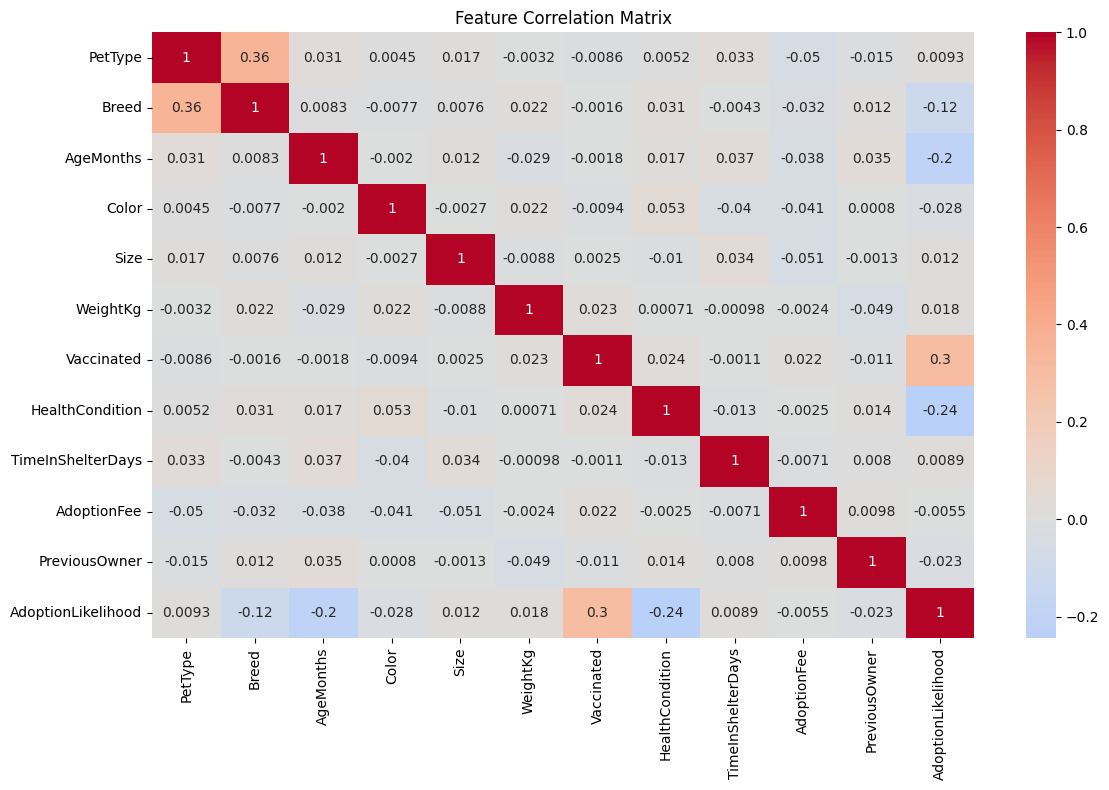

In [ ]:
plt.figure(figsize=(12, 8))
correlation_matrix = df_processed.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

Da una prima analisi sulla correlazione, risulta che la probabilità per un animale di essere adottati risulta maggiore se questo è già vaccinato: la matrice di correlazione risalta infatti un 0.3 di correlazione tra vaccinated e AdoptionLikelihood.
Anche HealthCondition mostra un'alta correlazione: essendo il valore 0 associato alle condizioni di buona salute, un animale in questo stato ha più probabilità di essere adottato rispetto ad uno con condizioni cliniche problematiche


### Profile Report

In [ ]:
pip install ydata-profiling

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.1/400.1 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.5/296.5 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 687.8/687.8 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.6 MB/s eta 0:00:00
  Created wheel for htmlmin: filename=htmlmin-0.1.12-py3-none-any.whl size=27081 sha256=009f1e2cff5547296dbe38b75cb47451e30a05479e27d99c9b67ff37de166be3
  Stored in directory: /root/.cache/pip/wheels/8d/55/1a/19cd535375ed1ede0c996405ebffe34b196d78e2d9545723a2
Successfully built htmlmin


Ora usiamo ProfileReport

In [ ]:
from ydata_profiling import ProfileReport

profile = ProfileReport(df, explorative=True)

display(profile)

Output hidden; open in https://colab.research.google.com to view.

Come ProfileReport evidenzia, Breed e PetType hanno un'altissima correlazione: questo evidenzia il problema del dataset, ossia che non solo ci sono poche razze per ogni specie (Dog ne ha 3 mentre Cat solo 2) ma addirittura Rabbit e Bird ne hanno una sola

Profile Report conferma anche le correlazioni della heatmap

In [ ]:
print(df['Breed'].unique())

['Parakeet' 'Rabbit' 'Golden Retriever' 'Labrador' 'Siamese' 'Persian'
 'Poodle']


Controlliamo il valore di massimo di TimeInShelterDays e AgeMonths per capire come mai il primo non abbia alcuna correlazione con AdoptionLikelihood mentre AgeMonths sì

In [ ]:
print('Max tempo trascorso nello Shelter')
print(df['TimeInShelterDays'].max())
print('Max eta\' (in mesi)')
print(df['AgeMonths'].max())

Max tempo trascorso nello Shelter
89
Max eta' (in mesi)
179


Controlliamo i valori di AdoptionFee

In [ ]:
print('Max AdoptionFee')
print(df['AdoptionFee'].max())
print('Media AdoptionFee')
print(df['AdoptionFee'].mean())
print('Min AdoptionFee')
print(df['AdoptionFee'].min())
print('Deviazione Standard AdoptionFee')
print(df['AdoptionFee'].std())

Max AdoptionFee
499
Media AdoptionFee
249.14200298953662
Min AdoptionFee
0
Deviazione Standard AdoptionFee
142.8870398116484


Questi valori da sé non danno molte informazioni. Proviamo dividendo per PetType visto che la specie di animale fa molta differenza nella scelta del Fee

In [ ]:
print('Deviazione Standard e Media AdoptionFee per Dog')
print(df[df['PetType'] == 'Dog']['AdoptionFee'].std())
print(df[df['PetType'] == 'Dog']['AdoptionFee'].mean())
print('Deviazione Standard e Media AdoptionFee per Cat')
print(df[df['PetType'] == 'Cat']['AdoptionFee'].std())
print(df[df['PetType'] == 'Cat']['AdoptionFee'].mean())
print('Deviazione Standard e Media AdoptionFee per Rabbit')
print(df[df['PetType'] == 'Rabbit']['AdoptionFee'].std())
print(df[df['PetType'] == 'Rabbit']['AdoptionFee'].mean())
print('Deviazione Standard e Media AdoptionFee per Bird')
print(df[df['PetType'] == 'Bird']['AdoptionFee'].std())
print(df[df['PetType'] == 'Bird']['AdoptionFee'].mean())

Deviazione Standard e Media AdoptionFee per Dog
143.06888785566096
247.5249042145594
Deviazione Standard e Media AdoptionFee per Cat
143.10706096267734
247.26336633663365
Deviazione Standard e Media AdoptionFee per Rabbit
143.43559593387778
240.27789046653143
Deviazione Standard e Media AdoptionFee per Bird
141.47819616175423
261.79671457905545


Nuovamente, nessuna informazione. Si può solo che concludere che il pagamento per l'adozione non è un'informazione rilevante per i nuovi padroni

o	Il PreviousOwner non influenza l'adottabilità di un animale: il motivo dell'abbandono potrebbe non essere tale da precludere un animale all'adozione.


---



La caratteristica che più influenza la probabilità è Size, il che è prevedibile per la scelta. Seguono, oltre a quelle elencate prima, Breed, AgeMonths e PetType. Anche queste sono di ovvia comprensione per la scelta dell'animale.

Convalidiamo i risultati con un Random Forest

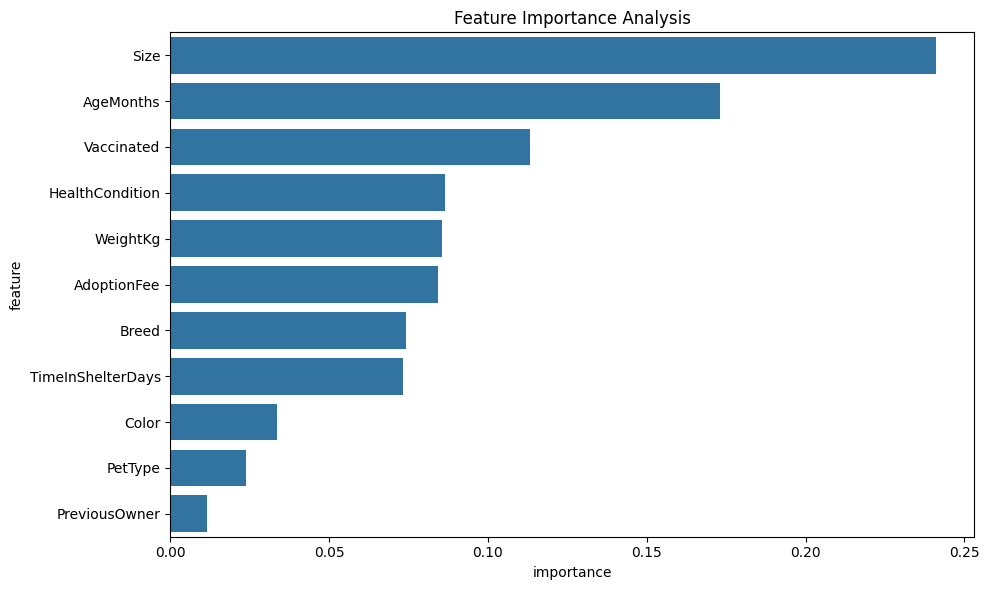

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='importance', y='feature')
plt.title('Feature Importance Analysis')
plt.tight_layout()
plt.show()


Otteniamo la conferma sopra che ci evidenzia come le feature più importanti siano Size, AgeMonths, Vaccinated ed HealthCondition ma viene anche evidenziato WeightKg.
Risultati analoghi vengono raggiunti con 50, 100 e 200 stimatori e con diversi random_state.

## Modelli

Anzitutto, serviamoci di una comoda funzione che validerà la robustezza dei nostri modelli.

In [11]:
def evaluate_model_on_splits(model, datasets, plot_title="Accuracy su 10 split"):

    test_accuracies = []

    for i, data in enumerate(datasets):
        model.fit(data['X_train'], data['y_train'])
        y_pred = model.predict(data['X_test'])
        acc = accuracy_score(data['y_test'], y_pred)
        test_accuracies.append(acc)
        print(f"Split {i+1}: Test Accuracy = {acc:.3f}")

    plt.figure(figsize=(10, 6))
    plt.bar(range(1, 11), test_accuracies, color='green')
    plt.ylim(0, 1)
    plt.xticks(range(1, 11), [f'Split {i}' for i in range(1, 11)])
    plt.ylabel("Accuracy")
    plt.xlabel("Split")
    plt.title(plot_title)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    media = np.mean(test_accuracies)
    print(media)
    print("Deviazione Standard delle Accuracy:")
    print(np.std(test_accuracies))

    return media

Useremo diversi modelli e li confronteremo. Per questo, salviamo l'accuracy di ciascun modello

In [ ]:
model_results = {}

Conserviamo anche le medie delle accuracy che troviamo con i test sulla robustezza

In [ ]:
media_robustezza = {}

### Tree & Forest

Proviamo ora usando un Decision Tree ed una Random Forest

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=RS, max_depth=10)
dt_classifier.fit(X_train, y_train)

# Dopo aver allenato il tree sul training set, usiamo il test set che avevamo
# genereato prima della Feature Analysis
dt_pred = dt_classifier.predict(X_test)
dt_score = accuracy_score(y_test, dt_pred)
print(dt_score)

# Per consentire un confronto finale, salviamo lo score
model_results['DecisionTree'] = dt_score

0.915


Plottiamo anche il tree per poterlo vedere

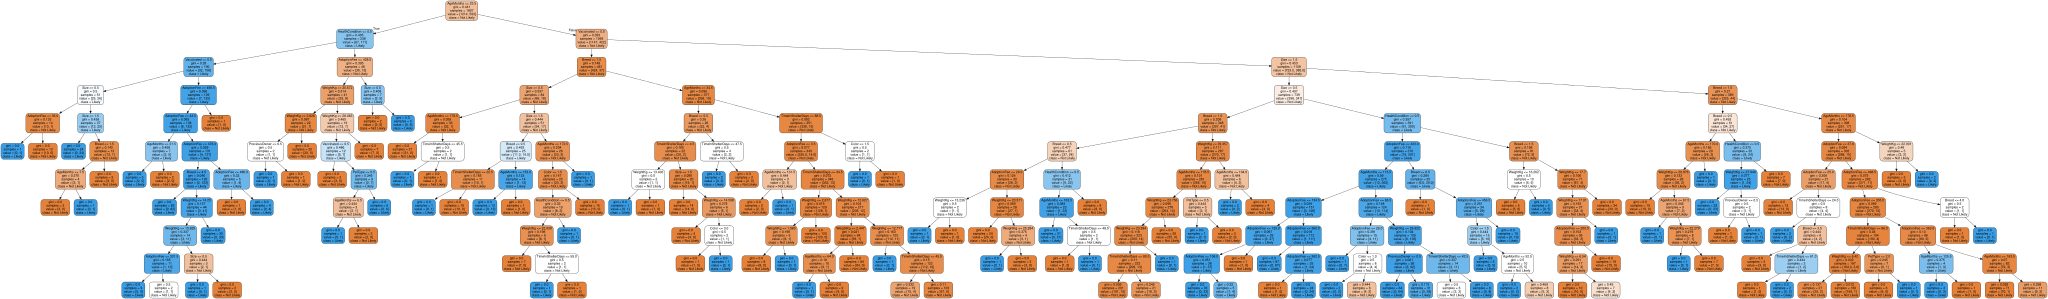

In [ ]:
from graphviz import Source
from sklearn.tree import export_graphviz

PROJECT_ROOT_DIR = "."
CHAPTER_ID = "decision_trees"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)
os.makedirs(IMAGES_PATH, exist_ok=True)

features = df.columns.to_list()
features.remove("AdoptionLikelihood")

export_graphviz(
        dt_classifier,
        out_file=os.path.join(IMAGES_PATH, "adoption_tree.dot"),
        feature_names=features,
        class_names=['Not Likely', 'Likely'],
        rounded=True,
        filled=True
    )

Source.from_file(os.path.join(IMAGES_PATH, "adoption_tree.dot"))

Con una max_depth di 10, otteniamo già ottimi risultati: abbiamo un'accuracy di 0.92 (anche con diversi random_state, il risultato o non cambia o peggiora)
Il DecisionTree è in grado di classificare correttamente la maggior parte delle istanze con nodi foglia che o hanno il 100% delle istanze lì giunte in una sola classe o comunque una "solida" maggioranza di istanze appartenenti ad una classe ed una minoranza all'altra.


Ciò che si nota è che i primi split seguono ciò che già avevamo visto nella Feature Analysis: AgeMonths e Vaccinated erano nella top delle feature più rilevanti e sono infatti state scelte per rispettivamente primo e i secondi split. I terzi split si differenziano ma la metà sono comunque su Size che era segnato come il primo per importanza.


Notare il terzo split da sinistra: viene effettuato su Breed con valori minori o uguali ad 1.5: questo è un chiaro segno che la conversione da categoriale ha fatto perdere rilevanza al dato della razza. fit di DecisionTree non accetta feature categoriali e non è quindi possibile splitare mantenendole

Per una migliore analisi, utilizziamo la Feature Analysis di prima e rimuoviamo le 3 colonne irrilevanti per AdoptionLikelihood

In [12]:
df_rilev = df_processed.copy()
# Rimuoviamo le feature che avevamo visto non avere correlazione con AdoptionLikelihood
df_rilev = df_rilev.drop(columns=['AdoptionFee', 'TimeInShelterDays', 'PreviousOwner'])
X_rilev = df_rilev.drop(columns=['AdoptionLikelihood'])
Y_rilev = df_rilev['AdoptionLikelihood']
X_train_rilev, X_test_rilev, y_train_rilev, y_test_rilev = train_test_split(X_rilev, Y_rilev,
                                                                    test_size=0.2, random_state=RS)

Creiamo anche 10 diversi training e test set per la robustezza

In [13]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

set_robustezza = []

for train_idx, test_idx in skf.split(X_rilev, Y_rilev): # StratKFold restituisce indici
    X_train = X_rilev.iloc[train_idx]
    X_test = X_rilev.iloc[test_idx]
    y_train = Y_rilev.iloc[train_idx]
    y_test = Y_rilev.iloc[test_idx]

    set_robustezza.append({
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test
    })

Tuttavia, non abbiamo cercato coi migliori parametri. Per questo, conviene usare GridSearchCV

In [ ]:
from sklearn.model_selection import GridSearchCV

params = {'max_depth': list(range(4,20)), 'max_leaf_nodes': list(range(2, 100)), 'min_samples_split': [2, 3, 4]}
grid_search_cv = GridSearchCV(DecisionTreeClassifier(random_state=RS), params, verbose=1, cv=3)

grid_search_cv.fit(X_train_rilev, y_train_rilev)

Fitting 3 folds for each of 4704 candidates, totalling 14112 fits


GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,
                                       16, 17, 18, 19],
                         'max_leaf_nodes': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,
                                            13, 14, 15, 16, 17, 18, 19, 20, 21,
                                            22, 23, 24, 25, 26, 27, 28, 29, 30,
                                            31, ...],
                         'min_samples_split': [2, 3, 4]},
             verbose=1)

In 2 minuti, la nostra ricerca è completa. Ora che abbiamo trovato dei buoni iperparametri, riproviamo a fare predict

In [ ]:
y_pred = grid_search_cv.predict(X_test_rilev)
grid_score = accuracy_score(y_test_rilev, y_pred)
model_results['GridSearchDecisionTree'] = grid_score
print(grid_score)
# Essendo così buono, salviamo questo DT
best_dt = grid_search_cv.best_estimator_

0.9477611940298507


Il risultato ora ottenuto è di 0.9477 che sarà addirittura il nostro miglior risultato trovato.

Test di Robustezza:

Split 1: Test Accuracy = 0.940
Split 2: Test Accuracy = 0.955
Split 3: Test Accuracy = 0.935
Split 4: Test Accuracy = 0.960
Split 5: Test Accuracy = 0.940
Split 6: Test Accuracy = 0.925
Split 7: Test Accuracy = 0.930
Split 8: Test Accuracy = 0.920
Split 9: Test Accuracy = 0.955
Split 10: Test Accuracy = 0.950


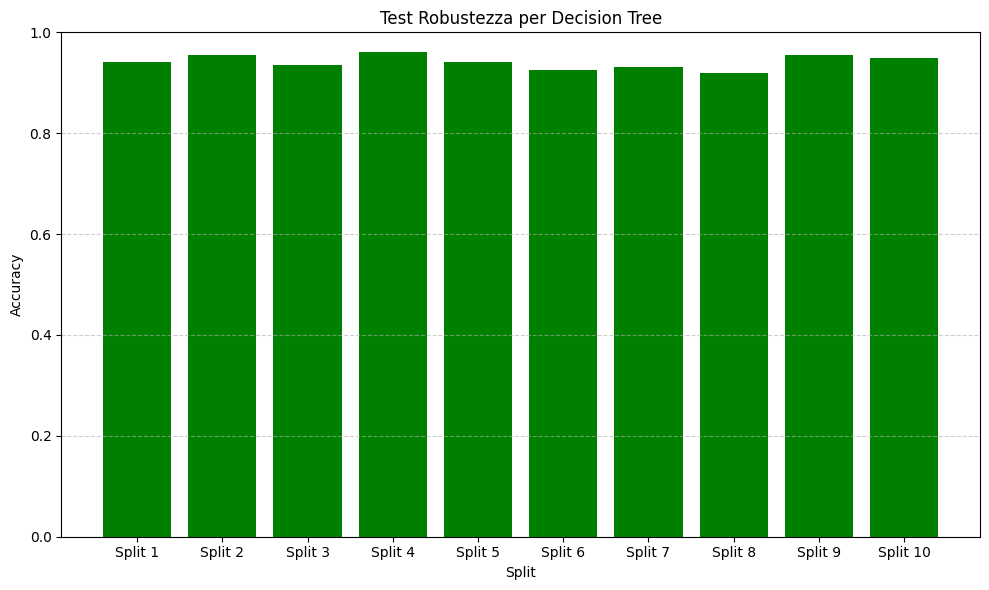

0.9412064676616915
Deviazione Standard delle Accuracy:
0.012959016045934567


In [ ]:
media = evaluate_model_on_splits(best_dt, set_robustezza, "Test Robustezza per Decision Tree")
media_robustezza['DecisionTree'] = media

Il nostro Decision Tree sembra abbastanza robusto: seppur oscillando più a ribasso (raggiungendo anche 0.92) per alcuni split addirittura l'accuracy migliora. La robustezza viene anche dalla bassa deviazione standard. La media delle accuracy è comunque di 0.941 che è comunque accettabile

Ora verifichiamo la Random Forest

In [ ]:
rnd_clf = RandomForestClassifier(n_estimators=100, random_state=RS)
rnd_clf.fit(X_train, y_train)
y_rnd = rnd_clf.predict(X_test)
rnd_score = accuracy_score(y_test, y_rnd)
print(rnd_score)
model_results['RandomForest'] = rnd_score

0.94


Otteniamo un 0.94. Il risultato non migliora cambiando random_state e nemmeno aumentando gli stimatori, abbassandoli invece peggiora. Questo potrebbe sottolineare che la randomicità sulla scelta delle feature risulta penalizzante. Proviamo ad integrare i risultati della Feature Analysis: prendiamo il dataset e facciamo drop delle colonne che sappiamo avere poca correlazione con AdoptionLikelihood e riproviamo

In [ ]:
rnd_clf = RandomForestClassifier(n_estimators=150, random_state=RS)

rnd_clf.fit(X_train_rilev, y_train_rilev)
y_rnd_aimed = rnd_clf.predict(X_test_rilev)
aimed_rnd_score = accuracy_score(y_test_rilev, y_rnd_aimed)
print(aimed_rnd_score)
model_results['AimedRandomForest'] = aimed_rnd_score

0.945273631840796


Puntare a mirare verso il subset di feature randomico più rilevante si è dimostrato efficace: con 150 stimatori, otteniamo un accuracy score di 0.945 (con 100 era 0.942, con 200 0.940 e con 50 0.937). Cambiare il random_state con 21 o 2025 ha portato a peggioramenti (0.937 per entrambi con 150 stimatori, 0.940 e 0.935 con 100 stimatori, 0.940 e 0.935 con 200 stimatori)

In [ ]:
params = {'n_estimators': [50, 100, 150, 200]}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=RS), params, verbose=1, cv=3)

rf_grid.fit(X_train_rilev, y_train_rilev)
y_rf_grid = rf_grid.predict(X_test_rilev)
rf_grid_score = accuracy_score(y_test_rilev, y_rf_grid)
model_results['GridSearchRandomForest'] = rf_grid_score
print(rf_grid_score)
print(rf_grid.best_params_)
best_rf = rf_grid.best_estimator_

Fitting 3 folds for each of 4 candidates, totalling 12 fits
0.945273631840796
{'n_estimators': 150}


Grid Search ci conferma la nostra miglior possibile accuracy. Salviamo questo modello e testiamone la robustezza

Split 1: Test Accuracy = 0.930
Split 2: Test Accuracy = 0.955
Split 3: Test Accuracy = 0.930
Split 4: Test Accuracy = 0.940
Split 5: Test Accuracy = 0.945
Split 6: Test Accuracy = 0.910
Split 7: Test Accuracy = 0.920
Split 8: Test Accuracy = 0.915
Split 9: Test Accuracy = 0.955
Split 10: Test Accuracy = 0.950


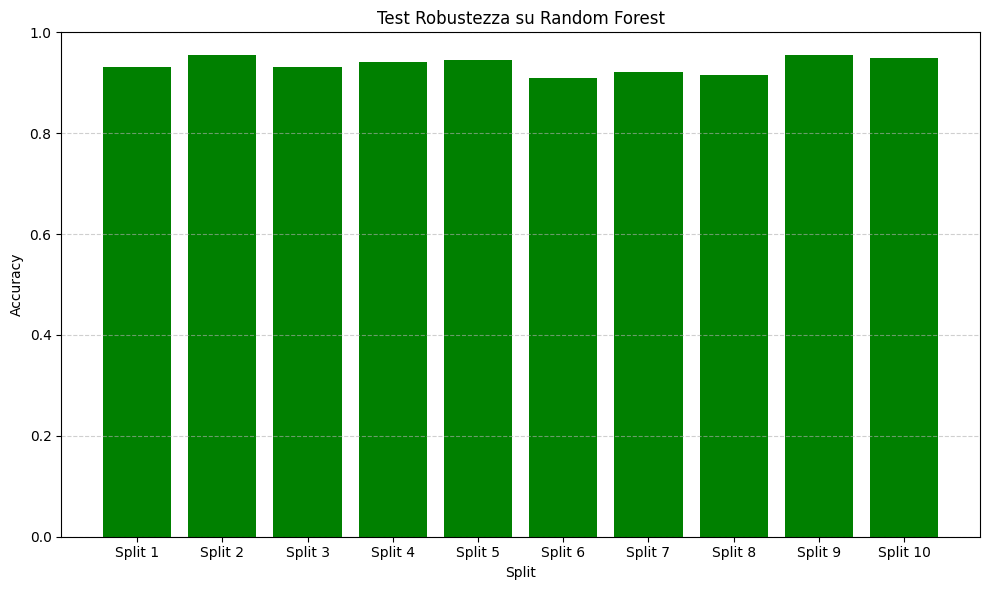

0.935233830845771
Deviazione Standard delle Accuracy:
0.015576868132627512


In [ ]:
media_rf = evaluate_model_on_splits(best_rf, set_robustezza, "Test Robustezza su Random Forest")
media_robustezza['RandomForest'] = media_rf

Ci chiediamo ora se un'aggiunta di randomicità possa alzare ancora di più i risultati: introduciamo Extra Trees

In [ ]:
extr_clf = ExtraTreesClassifier(n_estimators=150, random_state=RS)
extr_clf.fit(X_train, y_train)
y_extr = extr_clf.predict(X_test)
extr_score = accuracy_score(y_test, y_extr)
print(extr_score)
model_results['ExtraTrees'] = extr_score

0.925


Extra Trees non fornisce il risultato sperato ma lo conteggiamo comunque in quanto modello visto. Il numero di stimatori ideali è 150 che si dimostra migliore di 50 e 200 e pari a 100 con random_state=42. Tuttavia, 150 si dimostra migliore di 100 cambiando random_state, ecco i risultati (n_estimators=150):
- 42: 0.915
- 21 & 2025: 0.9179
- 5: 0.922  
Il risultato è abbastanza inedito visto che un random_state di 5 non aveva mai portato a miglioramenti

Verifichiamo ora se usando lo stesso df mirato porta a miglioramenti come per Random Forest

In [ ]:
aimed_extr_clf = ExtraTreesClassifier(n_estimators=150, random_state=RS)

# Utilizziamo i training e test set mirati fatti prima con Random Forest
aimed_extr_clf.fit(X_train_rilev, y_train_rilev)
y_extr_aimed = aimed_extr_clf.predict(X_test_rilev)
aimed_extr_score = accuracy_score(y_test_rilev, y_extr_aimed)
print(aimed_extr_score)
model_results['AimedExtraTrees'] = aimed_extr_score

0.9203980099502488


Utilizzando queste feature mirate e mantenendo n_estimators=150, random_state=5 otteniamo un valore comunque simile, che è comunque migliore di prima anche se di poco.
100 stimatori risulta in un peggioramento a 0.9179 mentre mantenere 150 stimatori e cambiare random state a 42 porta a peggiorare a 0.920, con 21 addirittura 0.910 e con 2025 a 0.915


In questo caso, Extra Trees ha portato ad un peggioramento rispetto a Random Forest: significa che il dataset non è particolarmente rumoroso ed è quindi più proficuo usare split mirati anziché affidarsi alla randomicità.

Verifichiamo la scelta degli iperparametri con un GridSearch

In [ ]:
params = {'n_estimators': [50, 100, 150, 200]}
et_grid = GridSearchCV(ExtraTreesClassifier(random_state=RS), params, verbose=1, cv=3)

et_grid.fit(X_train_rilev, y_train_rilev)
y_et_grid = et_grid.predict(X_test_rilev)
et_grid_score = accuracy_score(y_test_rilev, y_et_grid)
model_results['GridSearchExtraTrees'] = et_grid_score
print(et_grid_score)
print(et_grid.best_params_)
best_et = et_grid.best_estimator_

Fitting 3 folds for each of 4 candidates, totalling 12 fits
0.9203980099502488
{'n_estimators': 150}


Dunque, verifichiamo la robustezza

Split 1: Test Accuracy = 0.905
Split 2: Test Accuracy = 0.920
Split 3: Test Accuracy = 0.920
Split 4: Test Accuracy = 0.940
Split 5: Test Accuracy = 0.925
Split 6: Test Accuracy = 0.876
Split 7: Test Accuracy = 0.910
Split 8: Test Accuracy = 0.910
Split 9: Test Accuracy = 0.940
Split 10: Test Accuracy = 0.925


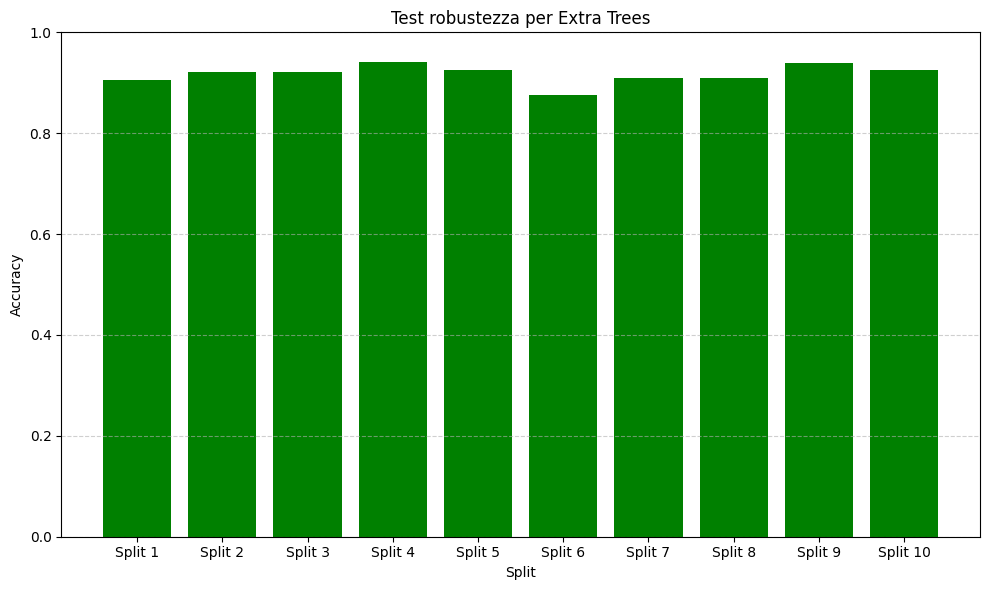

0.9173009950248756
Deviazione Standard delle Accuracy:
0.017790662351060273


In [ ]:
media_et = evaluate_model_on_splits(best_et, set_robustezza, "Test robustezza per Extra Trees")
media_robustezza['ExtraTree'] = media_et

Come vediamo, Extra Tree sembra non essere particolarmente stabile: questo è prevedibile a causa dei random split più che al random subset di feature.

Proviamo ora con un Regressor

In [ ]:
scaler_lr = StandardScaler()
X_train_scaled = scaler_lr.fit_transform(X_train)
X_test_scaled = scaler_lr.transform(X_test)

lr_classifier = LogisticRegression(random_state=RS, max_iter=1000)
lr_classifier.fit(X_train_scaled, y_train)

lr_pred = lr_classifier.predict(X_test_scaled)
lr_score = accuracy_score(y_test, lr_pred)
print(lr_score)
model_results['LogisticRegression'] = lr_score

0.745


Il risultato è molto delutente: 0.745, il peggiore fino ad ora. È evidente che una divisione lineare è molto difficile per questo genere di dataset. Proviamo invece con i dataset mirati (senza le feature di bassissima correlazione)

> Aggiungi citazione



In [ ]:
scaler_lr = StandardScaler()
X_train_scaled = scaler_lr.fit_transform(X_train_rilev)
X_test_scaled = scaler_lr.transform(X_test_rilev)

lr_classifier = LogisticRegression(random_state=RS, max_iter=1000)
lr_classifier.fit(X_train_scaled, y_train_rilev)

lr_pred_aimed = lr_classifier.predict(X_test_scaled)
lr_score_aimed = accuracy_score(y_test_rilev, lr_pred_aimed)
print(lr_score)
model_results['AimedLogisticRegression'] = lr_score_aimed

0.745


Il risultato non cambia: sebbene comunque sensibile a feature di poca rilevanza, il Logistic Regression fa molta fatica a trovare una divisione lineare per il dataset

### SVC

Proviamo ora con una normale SVC. Se le nostre considerazioni su Logistic Regression sono corrette, anche questa dovrebbe avere un basso risultato

In [ ]:
svc = make_pipeline(StandardScaler(), SVC(kernel='linear', random_state=RS))
svc.fit(X_train, y_train)

svc_pred = svc.predict(X_test)
svc_score = accuracy_score(y_test, svc_pred)
print(svc_score)
model_results['SVC'] = svc_score

0.75


Abbiamo ottenuto esattamente ciò che ci aspettavamo: il dataset è di difficile suddivisione lineare e l'accuracy si ferma a 0.75. A questo punto, modifichiamo il kernel. Per motivi di tempo, rimuoviamo le feature che sappiamo non avere correlazione con AdoptionLikelihood ed utilizziamo solo rbf per un drid search

In [ ]:
param_grid = {
    'svc__C': [0.1, 1, 10],
    'svc__gamma': [0.01, 0.1, 1],
    'svc__kernel': ['rbf']
}

grid_svc = GridSearchCV(make_pipeline(StandardScaler(), SVC()), param_grid, cv=5)
grid_svc.fit(X_train_rilev, y_train_rilev)

print('Migliori parametri: ', grid_svc.best_params_)
svc_kernel_score = grid_svc.score(X_test_rilev, y_test_rilev)
print('Score su test: ', svc_kernel_score)
model_results['SVCKernel'] = svc_kernel_score
best_svc = grid_svc.best_estimator_

Migliori parametri:  {'svc__C': 10, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
Score su test:  0.9154228855721394


Come ci aspettavamo, un C grande ed un gamma piccolo sono i migliori parametri. Essendo il dataset non rumoroso e sufficientemente piccolo, i parametri preferiti sono quelli che consentono una corretta classificazione e meno tolleranza per errori

Verifichiamone anche la robustezza comunque

Split 1: Test Accuracy = 0.905
Split 2: Test Accuracy = 0.950
Split 3: Test Accuracy = 0.925
Split 4: Test Accuracy = 0.930
Split 5: Test Accuracy = 0.925
Split 6: Test Accuracy = 0.886
Split 7: Test Accuracy = 0.905
Split 8: Test Accuracy = 0.895
Split 9: Test Accuracy = 0.920
Split 10: Test Accuracy = 0.915


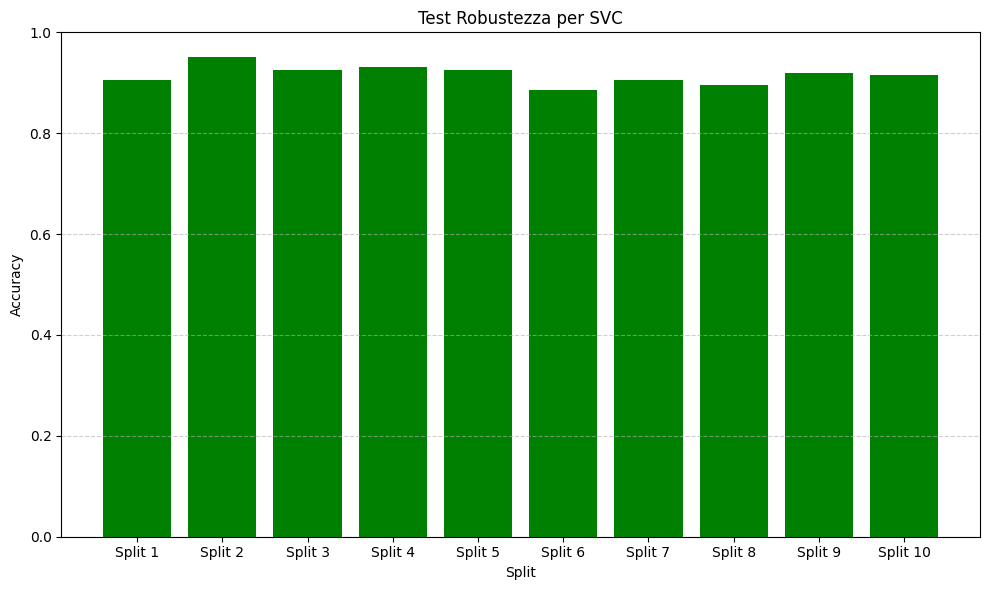

0.9157860696517414
Deviazione Standard delle Accuracy:
0.01777528880376146


In [ ]:
media_svc = evaluate_model_on_splits(best_svc, set_robustezza, "Test Robustezza per SVC")
media_robustezza['SVC'] = media_svc

SVC oscilla abbastanza quando si tratta di testare la variance, passando da 0.886 fino a 0.95, ma la media è in linea con il nostro grid search

Proviamo ora con Polynomial Feature, sempre rimuovendo quelle con correlazione nulla

In [ ]:
poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly_features.fit_transform(X_train_rilev)
X_test_poly = poly_features.transform(X_test_rilev)

svc_poly_pipeline = make_pipeline(RobustScaler(), SVC(kernel='rbf', C=10, gamma=0.1, random_state=RS))
svc_poly_pipeline.fit(X_train_poly, y_train_rilev)

svc_poly_pred = svc_poly_pipeline.predict(X_test_poly)
svc_poly_score = accuracy_score(y_test_rilev, svc_poly_pred)
print(svc_poly_score)
model_results['PolynomialWithRBF'] = svc_poly_score

0.8706467661691543


Otteniamo 0.858 con StandardScaler. Provando anche con un altro scaler: RobustScaler. Otteniamo 0.87 che è migliore. Lo salviamo

## Reti Neurali

In [ ]:
# Con feature irrilevanti
mlp_classifier = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    max_iter=1000,
    random_state=RS
)
# Riscaliamo per sicurezza
X_train_scaled = scaler_lr.fit_transform(X_train)
X_test_scaled = scaler_lr.transform(X_test)

mlp_classifier.fit(X_train_scaled, y_train)
mlp_pred = mlp_classifier.predict(X_test_scaled)
mlp_score = accuracy_score(y_test, mlp_pred)
print(mlp_score)
model_results['MLPAimed'] = mlp_score

0.895


In [ ]:
# Senza feature irrilevanti
mlp_classifier_aimed = MLPClassifier(
    hidden_layer_sizes=(100, 100, 100),
    max_iter=1000,
    random_state=RS
)
# Riscaliamo per sicurezza
X_train_scaled = scaler_lr.fit_transform(X_train_rilev)
X_test_scaled = scaler_lr.transform(X_test_rilev)

mlp_classifier_aimed.fit(X_train_scaled, y_train_rilev)
mlp_pred_aimed = mlp_classifier_aimed.predict(X_test_scaled)
mlp_score_aimed = accuracy_score(y_test_rilev, mlp_pred_aimed)
print(mlp_score_aimed)
model_results['MLPAimed'] = mlp_score_aimed

0.8855721393034826


Utilizzando l'intero dataset, otteniamo un'accuracy di 0.895. Se invece rimuoviamo quelle feature irrilevanti, otteniamo 0.8955. Questo dimostra che il MLP si era fatto deviare da queste feature e, rimuovendole, la situazione è leggermente migliorata.
- hidden_layer_sizes=(100, 50),
- max_iter=1000,
- random_state=42

Pur aumentando le iterazioni (10_000 e 100_000), l'accuracy non cambia. Altro tuning:
hidden_layer_size:
- (10,) -> peggioramento a 0.873
- (10, 50) -> peggioramento 0.8707
- (100, 100) -> peggioramento a 0.883
- (100, 50, 25) -> peggioramento a 0.883
- (100, 100, 100) -> peggioramento a 0.885

  Quindi aumentare il numero di layer ha portato miglioramenti ma aumentare il numero di neuroni per hidden layer non ha portato miglioramenti significativi.
  La soluzione iniziale rimane ugualmente la migliore

## Ensemble

Utilizziamo ora degli Ensemble methods: questo ci permetterà di utilizzare i modelli visti fin'ora e di combinarli per ottenere possibilmente dei buoni risultati

### Voting

In [ ]:
sorted_models = sorted(model_results.items(), key=lambda x: x[1], reverse=True)
print(sorted_models)

[('GridSearchDecisionTree', 0.9477611940298507), ('AimedRandomForest', 0.945273631840796), ('GridSearchRandomForest', 0.945273631840796), ('RandomForest', 0.94), ('ExtraTrees', 0.925), ('AimedExtraTrees', 0.9203980099502488), ('GridSearchExtraTrees', 0.9203980099502488), ('SVCKernel', 0.9154228855721394), ('DecisionTree', 0.915), ('MLPAimed', 0.8855721393034826), ('SVC', 0.75), ('LogisticRegression', 0.745), ('AimedLogisticRegression', 0.7164179104477612)]


In [ ]:
# Utilizziamo alcuni modelli che avevamo già usato in precedenza
voting_classifier = VotingClassifier(
    estimators=[('aimed_extr', aimed_extr_clf), ('SVC', grid_svc), ('GridDT', grid_search_cv)],
    voting='hard'
)

# Per mantenere l'efficacia dei modelli, utilizziamo ancora
# le feature rilevanti
voting_classifier.fit(X_train_scaled, y_train_rilev)
voting_pred = voting_classifier.predict(X_test_scaled)
voting_score = accuracy_score(y_test_rilev, voting_pred)
print(voting_score)
model_results['Voting_AEXTR_SVC_GridDT'] = voting_score

Fitting 3 folds for each of 4704 candidates, totalling 14112 fits
0.9353233830845771


Sorprendetemente, la nostra scelta di modelli ha portato ad un PEGGIORAMENTO della miglior soluzione trovata: significa che i modelli che hanno classificato in maniera sbagliata sono più di quelli che classificano in maniera giusta. Proviamo a combinare invece altri modelli

In [ ]:
# Proviamo ad usare modelli diversi
voting_classifier_second = VotingClassifier(
    estimators=[('SVCKernel', grid_svc), ('A-MLP', mlp_classifier_aimed), ('aimed_extr', aimed_extr_clf)],
    voting='hard'
)

voting_classifier_second.fit(X_train_scaled, y_train_rilev)
voting_pred_second = voting_classifier_second.predict(X_test_scaled)
voting_score_second = accuracy_score(y_test_rilev, voting_pred_second)
print(voting_score_second)
model_results['Voting_AEXTR_SVCKernel_AMLP'] = voting_score_second

0.927860696517413


In [ ]:
# Proviamo a 3 classificatori che hanno ottenuto scarsi risultati, escludendo quelli che
# hanno usato la linearità
voting_classifier_third = VotingClassifier(
    estimators=[('SVCKernel', grid_svc), ('A-MLP', mlp_classifier_aimed),
                ('PolRBF', svc_poly_pipeline)],
    voting='hard'
)

voting_classifier_third.fit(X_train_scaled, y_train_rilev)
voting_pred_third = voting_classifier_third.predict(X_test_scaled)
voting_score_third = accuracy_score(y_test_rilev, voting_pred_third)
print(voting_score_third)
model_results['Voting_SVCKernel_AMLP_PolRBF'] = voting_score_third

0.9029850746268657


In [ ]:
# Proviamo con la top 2
voting_classifier_fourth = VotingClassifier(
    estimators=[('GridDT', best_dt), ('rf', rnd_clf)],
    voting='hard'
)

voting_classifier_fourth.fit(X_train_scaled, y_train_rilev)
voting_pred_fourth = voting_classifier_fourth.predict(X_test_scaled)
voting_score_fourth = accuracy_score(y_test_rilev, voting_pred_fourth)
print(voting_score_fourth)
model_results['Voting_RandForest_GridDT'] = voting_score_fourth

0.945273631840796


Alla fine di questi tentativi, nessuno riesce a battere il Decision Tree ma usare voting con l'attuale top 3 si dimostra comunque solido con 0.945. Facciamo un test di robustezza su questo.

Split 1: Test Accuracy = 0.935
Split 2: Test Accuracy = 0.955
Split 3: Test Accuracy = 0.935
Split 4: Test Accuracy = 0.945
Split 5: Test Accuracy = 0.940
Split 6: Test Accuracy = 0.920
Split 7: Test Accuracy = 0.925
Split 8: Test Accuracy = 0.915
Split 9: Test Accuracy = 0.955
Split 10: Test Accuracy = 0.950


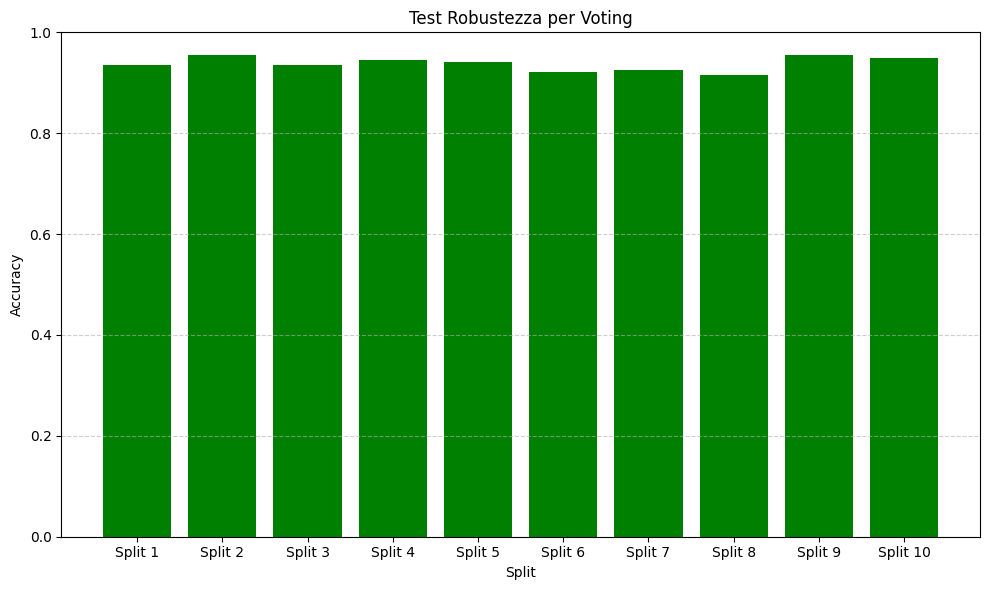

0.9377213930348258
Deviazione Standard delle Accuracy:
0.013415181876315872


In [ ]:
media_voting = evaluate_model_on_splits(voting_classifier_fourth, set_robustezza, "Test Robustezza per Voting")
media_robustezza['Voting'] = media_voting

Questi risultati sono sicuramente confortanti: l'accuracy è buona e l'oscillazione è bassa, ma comunque non al pari del Decision Tree a sé stante

Proviamo ora invece ad usare Bagging

In [ ]:
# Visto che il Decisione Tree si è rivelato il migliore, continuiamo ad usarlo
bagging_classifier = BaggingClassifier(
    best_dt,
    n_estimators=1000, bootstrap=True, random_state=RS, oob_score=True
)

bagging_classifier.fit(X_train_rilev, y_train_rilev)
bagging_pred = bagging_classifier.predict(X_test_rilev)
bagging_score = accuracy_score(y_test_rilev, bagging_pred)
print(bagging_score)
model_results['BaggingGridDT'] = bagging_score

0.945273631840796


Con 100 stimatori, RS=42 e il Grid Decision Tree come base_estimator, otteniamo un'accuracy di 0.945. Vogliamo effettuare una verifica più esaustiva sugli iperparametri, quindi usiamo GridSearch. La semplicità del modello base ci consente di ottenere un risultato entro un tempo ragionevole

In [ ]:
bagging_dt_grid = BaggingClassifier(
    best_dt,
    random_state=RS,
    bootstrap=True, oob_score=True
)

param_grid = {
    'n_estimators': [250, 500, 1000, 2000, 3000]
}

bagging_dt_grid = GridSearchCV(bagging_dt_grid, param_grid, cv=5, n_jobs=-1)
bagging_dt_grid.fit(X_train_rilev, y_train_rilev)
grid_bagging_dt_score = bagging_dt_grid.score(X_test_rilev, y_test_rilev)
print('Migliori parametri: ', bagging_dt_grid.best_params_)
print('Score su test: ', grid_bagging_dt_score)
model_results['GridDTBagging'] = grid_bagging_dt_score
best_bagging_dt = bagging_dt_grid.best_estimator_

Migliori parametri:  {'n_estimators': 250}
Score su test:  0.945273631840796


La ricerca impiega 1 minuto e produce un buon risultato: 0.945. Il risultato viene salvato



Verifichiamone quindi l'accuracy

Split 1: Test Accuracy = 0.935
Split 2: Test Accuracy = 0.960
Split 3: Test Accuracy = 0.935
Split 4: Test Accuracy = 0.950
Split 5: Test Accuracy = 0.950
Split 6: Test Accuracy = 0.925
Split 7: Test Accuracy = 0.915
Split 8: Test Accuracy = 0.910
Split 9: Test Accuracy = 0.955
Split 10: Test Accuracy = 0.950


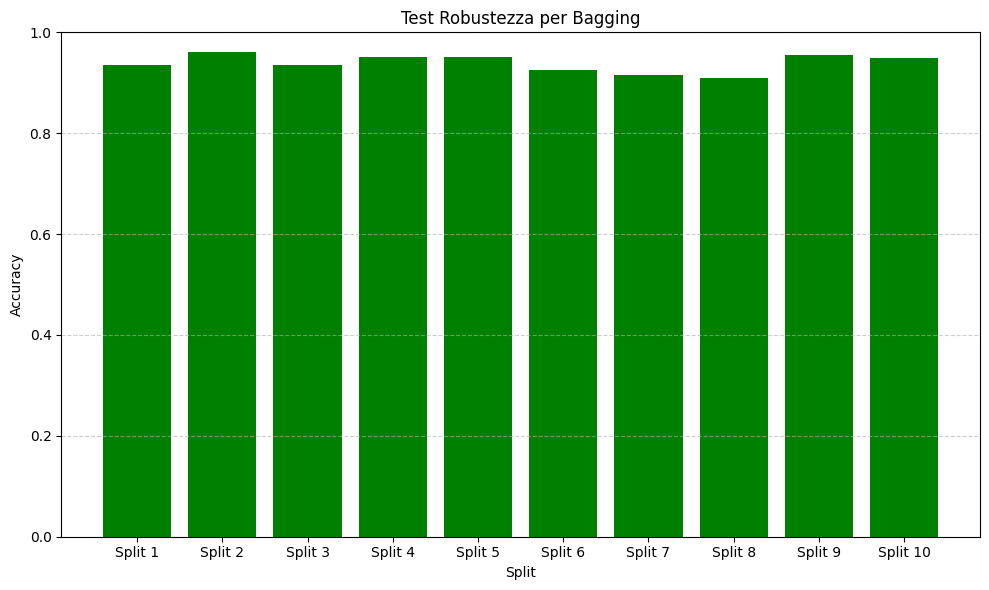

0.9387139303482586
Deviazione Standard delle Accuracy:
0.016395899801738695


In [ ]:
media_bagging = evaluate_model_on_splits(best_bagging_dt, set_robustezza, "Test Robustezza per Bagging")
media_robustezza['Bagging'] = media_bagging

Bagging sembra robusto: la media dell'accuracy viene ridotta a causa degli split 7 ed 8 ma in generale l'accuracy è molto buona. Notare che uno degli split ha generato 0.96 di accuracy, al pari del massimo del Decision Tree

Utilizzando invec un DecisionTreeClassifier senza parametri otteniamo un risultato peggiore

In [ ]:
bagging_grid = BaggingClassifier(
    DecisionTreeClassifier(),
    random_state=RS,
    bootstrap=True, oob_score=True
)

param_grid = {
    'n_estimators': [250, 500, 1000, 2000]
}

grid_bagging = GridSearchCV(bagging_grid, param_grid, cv=5, n_jobs=-1)
grid_bagging.fit(X_train_rilev, y_train_rilev)
grid_bagging_score = grid_bagging.score(X_test_rilev, y_test_rilev)
print('Migliori parametri: ', grid_bagging.best_params_)
print('Score su test: ', grid_bagging_score)
model_results['GridBagging'] = grid_bagging_score

Migliori parametri:  {'n_estimators': 250, 'random_state': 2025}
Score su test:  0.9378109452736318


#### AdaBoost
Proviamo ora con AdaBoost.  
Anche qui, sfruttiamo il fatto che il nostro miglior risultato venga da un modello semplice e lo usiamo per AdaBoost con GridSearch

In [ ]:
ada_classifier_grid = BaggingClassifier(
    best_dt,
    random_state=RS,
    bootstrap=True, oob_score=True
)

param_grid = {
    'n_estimators': [250, 500, 1000, 2000, 3000]
}

ada_classifier_grid = GridSearchCV(ada_classifier_grid, param_grid, cv=5, n_jobs=-1)
ada_classifier_grid.fit(X_train_rilev, y_train_rilev)
ada_classifier_grid_score = ada_classifier_grid.score(X_test_rilev, y_test_rilev)
print('Migliori parametri: ', ada_classifier_grid.best_params_)
print('Score su test: ', ada_classifier_grid_score)
model_results['GridAdaDT'] = ada_classifier_grid_score
best_ada = ada_classifier_grid.best_estimator_

Migliori parametri:  {'n_estimators': 250}
Score su test:  0.945273631840796
{'n_estimators': 250}


Il risultato è comunque buono: in 2 minuti, abbiamo ottenuto 0.945 di accuracy

Verifichiamo la robustezza

Split 1: Test Accuracy = 0.935
Split 2: Test Accuracy = 0.960
Split 3: Test Accuracy = 0.935
Split 4: Test Accuracy = 0.950
Split 5: Test Accuracy = 0.950
Split 6: Test Accuracy = 0.925
Split 7: Test Accuracy = 0.915
Split 8: Test Accuracy = 0.910
Split 9: Test Accuracy = 0.955
Split 10: Test Accuracy = 0.950


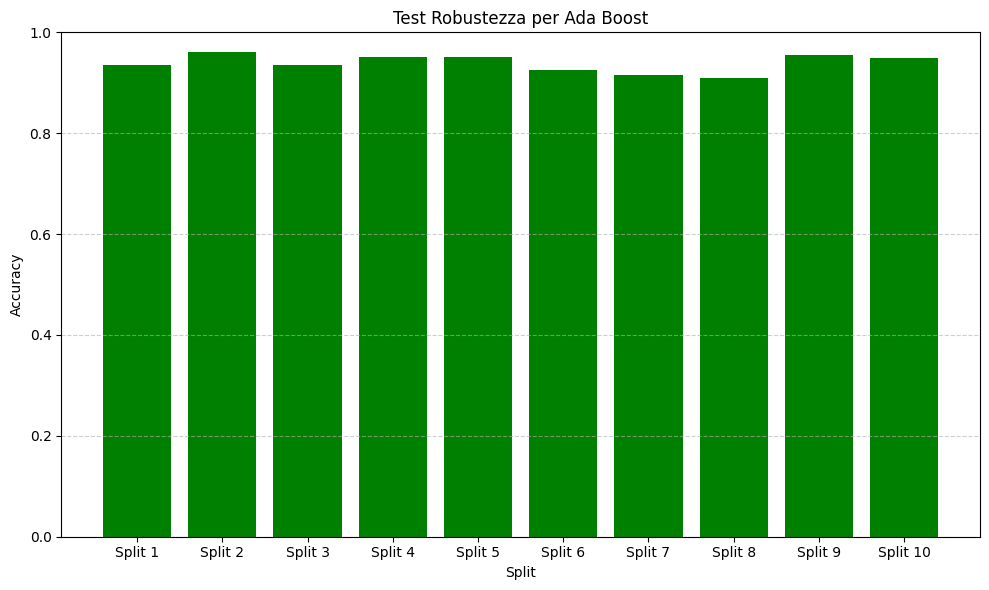

0.9387139303482586
Deviazione Standard delle Accuracy:
0.016395899801738695


In [ ]:
media_ada = evaluate_model_on_splits(best_ada, set_robustezza, "Test Robustezza per Ada Boost")
media_robustezza['AdaBoost'] = media_ada

#### Stacking

Utilizziamo ora un Meta Learner come Stacking. Come per Voting, scegliamo 3 learner tra i nostri migliori

In [ ]:
sorted_models = sorted(model_results.items(), key=lambda x: x[1], reverse=True)
print(sorted_models)

[('GridSearchDecisionTree', 0.9477611940298507), ('AimedRandomForest', 0.945273631840796), ('GridSearchRandomForest', 0.945273631840796), ('Voting_AEXTR_RandForest_GridDT', 0.945273631840796), ('GridDTBagging', 0.945273631840796), ('GridAdaDT', 0.945273631840796), ('BaggingGridDT', 0.9427860696517413), ('RandomForest', 0.9378109452736318), ('GridBagging', 0.9378109452736318), ('Voting_AEXTR_SVC_GridDT', 0.9353233830845771), ('AimedExtraTrees', 0.9253731343283582), ('ExtraTrees', 0.9228855721393034), ('DecisionTree', 0.9203980099502488), ('Voting_AEXTR_SVCKernel_AMLP', 0.9203980099502488), ('SVCKernel', 0.9154228855721394), ('Voting_SVCKernel_AMLP_PolRBF', 0.900497512437811), ('MLPAimed', 0.8830845771144279), ('PolynomialWithRBF', 0.8706467661691543), ('LogisticRegression', 0.7164179104477612), ('AimedLogisticRegression', 0.7164179104477612), ('SVC', 0.7139303482587065)]


Li prendiamo e li usiamo con LogisticRegression. L'utilizzo viene però limitato dal tempo, quindi usiamo gli stessi learner escludendo voting


In [ ]:
# Scegliamo i migliori modelli
# Per SVC teniamo i parametri che avevamo trovato ed aggiungiamo
# probability=True per avere l'input probabilistico per il meta learner
base_learners = [
    ('dt', best_dt),
    ('rf', rnd_clf),
    # ('svc', SVC(kernel='rbf', C=10.0, gamma=0.1, probability=True, random_state=42))
    ('bagDt', best_bagging_dt)
]

meta_learner = LogisticRegression(random_state=RS, max_iter=100_000)

stacking_classifier = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=5, n_jobs=-1
)

stacking_classifier.fit(X_train_scaled, y_train_rilev)
stacking_pred = stacking_classifier.predict(X_test_scaled)
stacking_score = accuracy_score(y_test_rilev, stacking_pred)
print(stacking_score)
model_results['Stacking'] = stacking_score

0.9502487562189055


Stacking impiega 10 secondi con il Decision Tree, Random Forest ed il Bagging con DT per ottenere 0.95, il migliori risultato fin'ora. Questo con 10_000 iterazioni e RS=42.
Anche SVC è stato usato ma ha portato peggioramenti.  
È stato anche provato con 100_000 iterazioni ma non ha portato a cambiamenti


Validiamo dunque la robustezza di Stacking

Split 1: Test Accuracy = 0.940
Split 2: Test Accuracy = 0.960
Split 3: Test Accuracy = 0.935
Split 4: Test Accuracy = 0.950
Split 5: Test Accuracy = 0.950
Split 6: Test Accuracy = 0.925
Split 7: Test Accuracy = 0.930
Split 8: Test Accuracy = 0.920
Split 9: Test Accuracy = 0.955
Split 10: Test Accuracy = 0.950


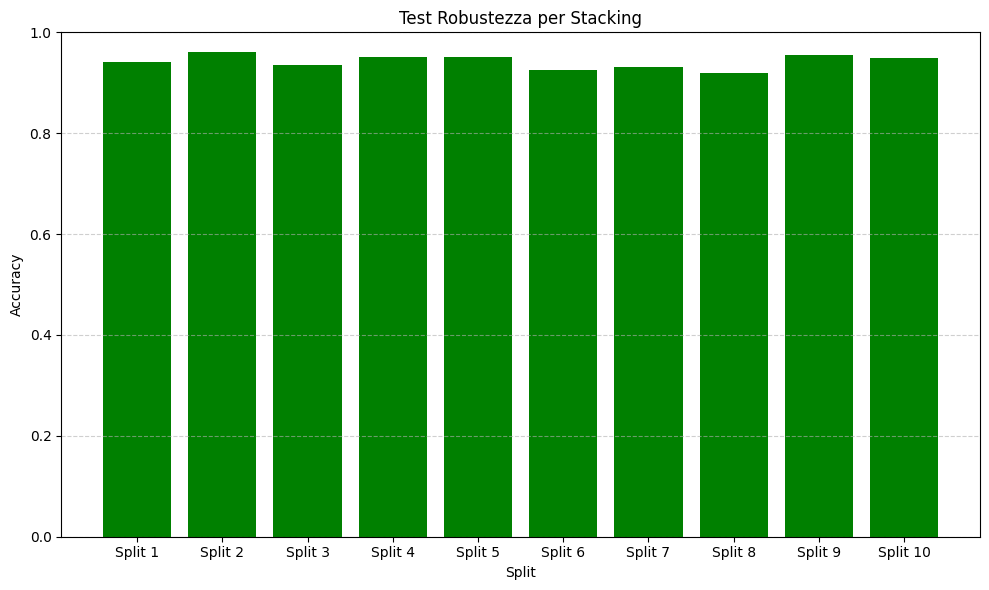

0.9417039800995024
Deviazione Standard delle Accuracy:
0.012818344238284547


In [ ]:
media_stacking = evaluate_model_on_splits(stacking_classifier, set_robustezza, "Test Robustezza per Stacking")
media_robustezza['Stacking'] = media_stacking

Questi sono gli stess risultati del Decision Tree: quindi, al netto dei test, Stacking e Decision Tree portano quasi alle stesse performance perchè decision tree aveva in realtà una media di 0.9417.

## Cluster

Usiamo i Cluster come ultimi modelli. Sapendo già che il nostro target è binario, non ci serve fare Elbow e Silhouette, avremo 2 Cluster

Prima scaliamo i nostri dati

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_rilev)
X_test_scaled = scaler.transform(X_test_rilev)

### K-Mean

In [19]:
kmeans = KMeans(n_clusters=2, random_state=RS)
kmeans.fit(X_train_scaled)

y_pred_kmeans = kmeans.predict(X_test_scaled)

# Le label di Cluster non hanno un vero e proprio significato quindi dobbiamo
# provare anche ad invertire per trovare quale corrispondenza sia la
# più significativa
acc_direct = accuracy_score(y_test_rilev, y_pred_kmeans)
y_pred_kmeans_flipped = 1 - y_pred_kmeans
acc_flipped = accuracy_score(y_test_rilev, y_pred_kmeans_flipped)

# CASO: era effettivamente flippato
if acc_flipped > acc_direct:
    y_pred_kmeans_final = y_pred_kmeans_flipped
    kmeans_accuracy = acc_flipped
    print("Flippato")
# CASO: Label era corretto
else:
    y_pred_kmeans_final = y_pred_kmeans
    kmeans_accuracy = acc_direct
    print("Corretto")

print(f"Accuracy: {kmeans_accuracy:.4f}")

Flippato
Accuracy: 0.5498


Split 1: Test Accuracy = 0.488
Split 2: Test Accuracy = 0.418
Split 3: Test Accuracy = 0.622
Split 4: Test Accuracy = 0.607
Split 5: Test Accuracy = 0.388
Split 6: Test Accuracy = 0.378
Split 7: Test Accuracy = 0.453
Split 8: Test Accuracy = 0.560
Split 9: Test Accuracy = 0.575
Split 10: Test Accuracy = 0.530


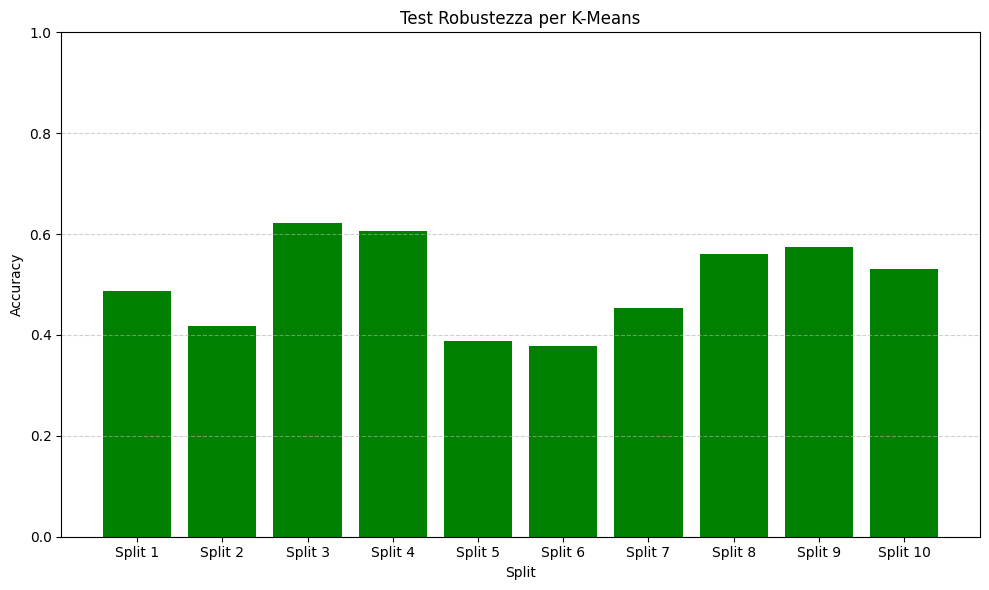

0.5018233830845772
Deviazione Standard delle Accuracy:
0.08538488859143803


np.float64(0.5018233830845772)

In [20]:
evaluate_model_on_splits(kmeans, set_robustezza, "Test Robustezza per K-Means")

L'accuracy media e la deviazione standard sono terribili e riprova ancora una volta come una divisione lineare sia effettivamente terribile. Non proseguiamo oltre.

# Confronto Finale

 1. Stacking            : 0.9502
 2. GridSearchDecisionTree: 0.9478
 3. AimedRandomForest   : 0.9453
 4. GridSearchRandomForest: 0.9453
 5. Voting_RandForest_GridDT: 0.9453
 6. BaggingGridDT       : 0.9453
 7. GridDTBagging       : 0.9453
 8. GridAdaDT           : 0.9453
 9. RandomForest        : 0.9400
10. Voting_AEXTR_SVC_GridDT: 0.9353
11. Voting_AEXTR_SVCKernel_AMLP: 0.9279
12. ExtraTrees          : 0.9250
13. AimedExtraTrees     : 0.9204
14. GridSearchExtraTrees: 0.9204
15. SVCKernel           : 0.9154
16. DecisionTree        : 0.9150
17. Voting_SVCKernel_AMLP_PolRBF: 0.9030
18. MLPAimed            : 0.8856
19. PolynomialWithRBF   : 0.8706
20. SVC                 : 0.7500
21. LogisticRegression  : 0.7450
22. AimedLogisticRegression: 0.7164


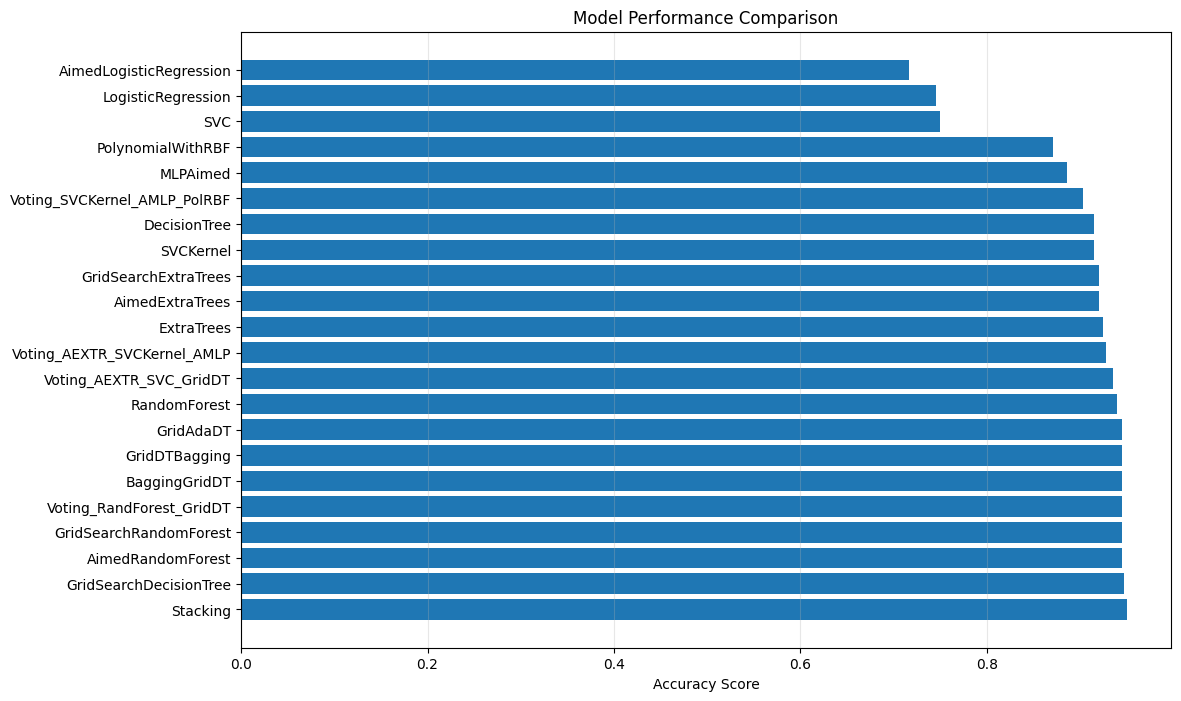

In [ ]:
sorted_models = sorted(model_results.items(), key=lambda x: x[1], reverse=True)
for i, (model_name, accuracy) in enumerate(sorted_models, 1):
    print(f"{i:2d}. {model_name:20s}: {accuracy:.4f}")

plt.figure(figsize=(12, 8))
models, scores = zip(*sorted_models)
bars = plt.barh(range(len(models)), scores)
plt.yticks(range(len(models)), models)
plt.xlabel('Accuracy Score')
plt.title('Model Performance Comparison')
plt.grid(axis='x', alpha=0.3)

Questa prima valutazione mostra il confronto su un solo training e test set, quello iniziale: Stacking batte il Decision Tree anche se di poco, mnetre poi seguono Random Forest, Voting con DT e Random Forest, Bagging ed AdaBoost.  
In fondo troviamo Regression ed SVC con Kernel Lineare.


Verifichiamo anche le media per i test di robustezza.

 1. Stacking            : 0.9417
 2. DecisionTree        : 0.9412
 3. Bagging             : 0.9387
 4. AdaBoost            : 0.9387
 5. Voting              : 0.9377
 6. RandomForest        : 0.9352
 7. ExtraTree           : 0.9173
 8. SVC                 : 0.9158


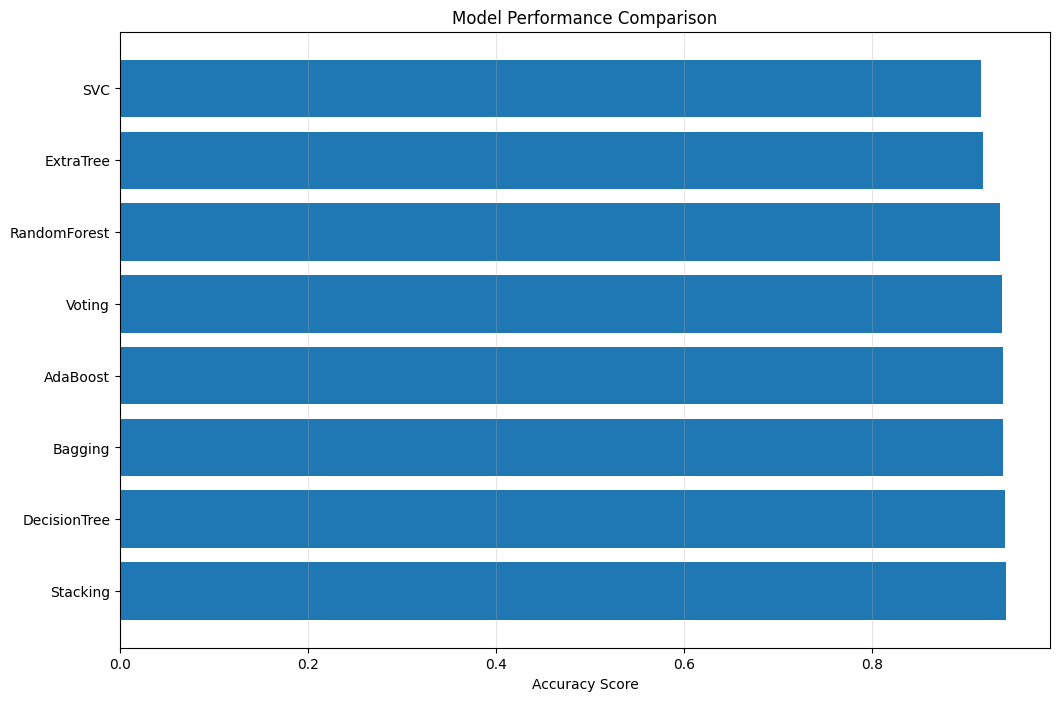

In [ ]:
sorted_accuracies = sorted(media_robustezza.items(), key=lambda x: x[1], reverse=True)
for i, (model_name, accuracy) in enumerate(sorted_accuracies, 1):
    print(f"{i:2d}. {model_name:20s}: {accuracy:.4f}")

plt.figure(figsize=(12, 8))
models, scores = zip(*sorted_accuracies)
bars = plt.barh(range(len(models)), scores)
plt.yticks(range(len(models)), models)
plt.xlabel('Accuracy Score')
plt.title('Model Performance Comparison')
plt.grid(axis='x', alpha=0.3)

Avendo fatto i test solo sui modelli più rilevanti, notiamo che Stacking raggiunge la migliore accuracy media sui 10 set: 0.9417. I nostri modelli erano comunque robusti visto che la deviazione standard stava comunque sempre sotto il 0.2 ma Stacking, anche su questo fronte, si è dimostrato tra i migliori risultati, ottenendo una deviazione standard di 0.013 che solamente il Decision Tree è riuscito ad ottenere.

Al fine di ottenere risultati a posteriori, creiamo una Matrice di Confusione


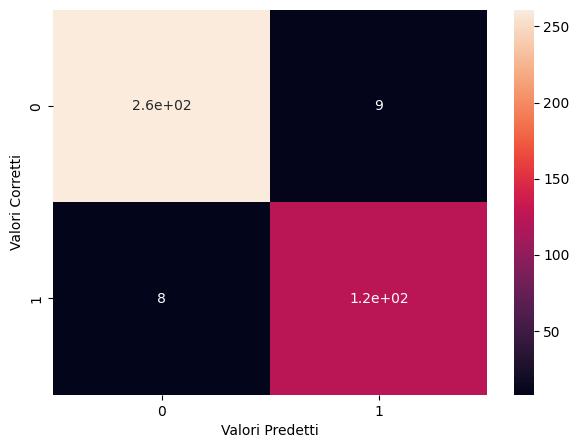

In [ ]:
pred = stacking_classifier.predict(X_test_rilev)
cm = confusion_matrix(y_test_rilev, pred)
plt.figure(figsize=(7,5))
sns.heatmap(cm,annot=True)
plt.xlabel('Valori Predetti')
plt.ylabel('Valori Corretti')
plt.show()

I valori predetti erroneamente non tendono in particolar modo su una delle due parti col dataset di test. Questo mostra come non ci siano sbilanci particolari dovuti a pattern non trovati per l'adozione o meno ma a possibili discrepanze nella scelta dei padroni.

Creiamo le matrici di confusione anche per i nostri set di robustezza.

Split 1 - Sensitivity: 0.879
Split 2 - Sensitivity: 0.909
Split 3 - Sensitivity: 0.833
Split 4 - Sensitivity: 0.894
Split 5 - Sensitivity: 0.894
Split 6 - Sensitivity: 0.848
Split 7 - Sensitivity: 0.848
Split 8 - Sensitivity: 0.831
Split 9 - Sensitivity: 0.909
Split 10 - Sensitivity: 0.909


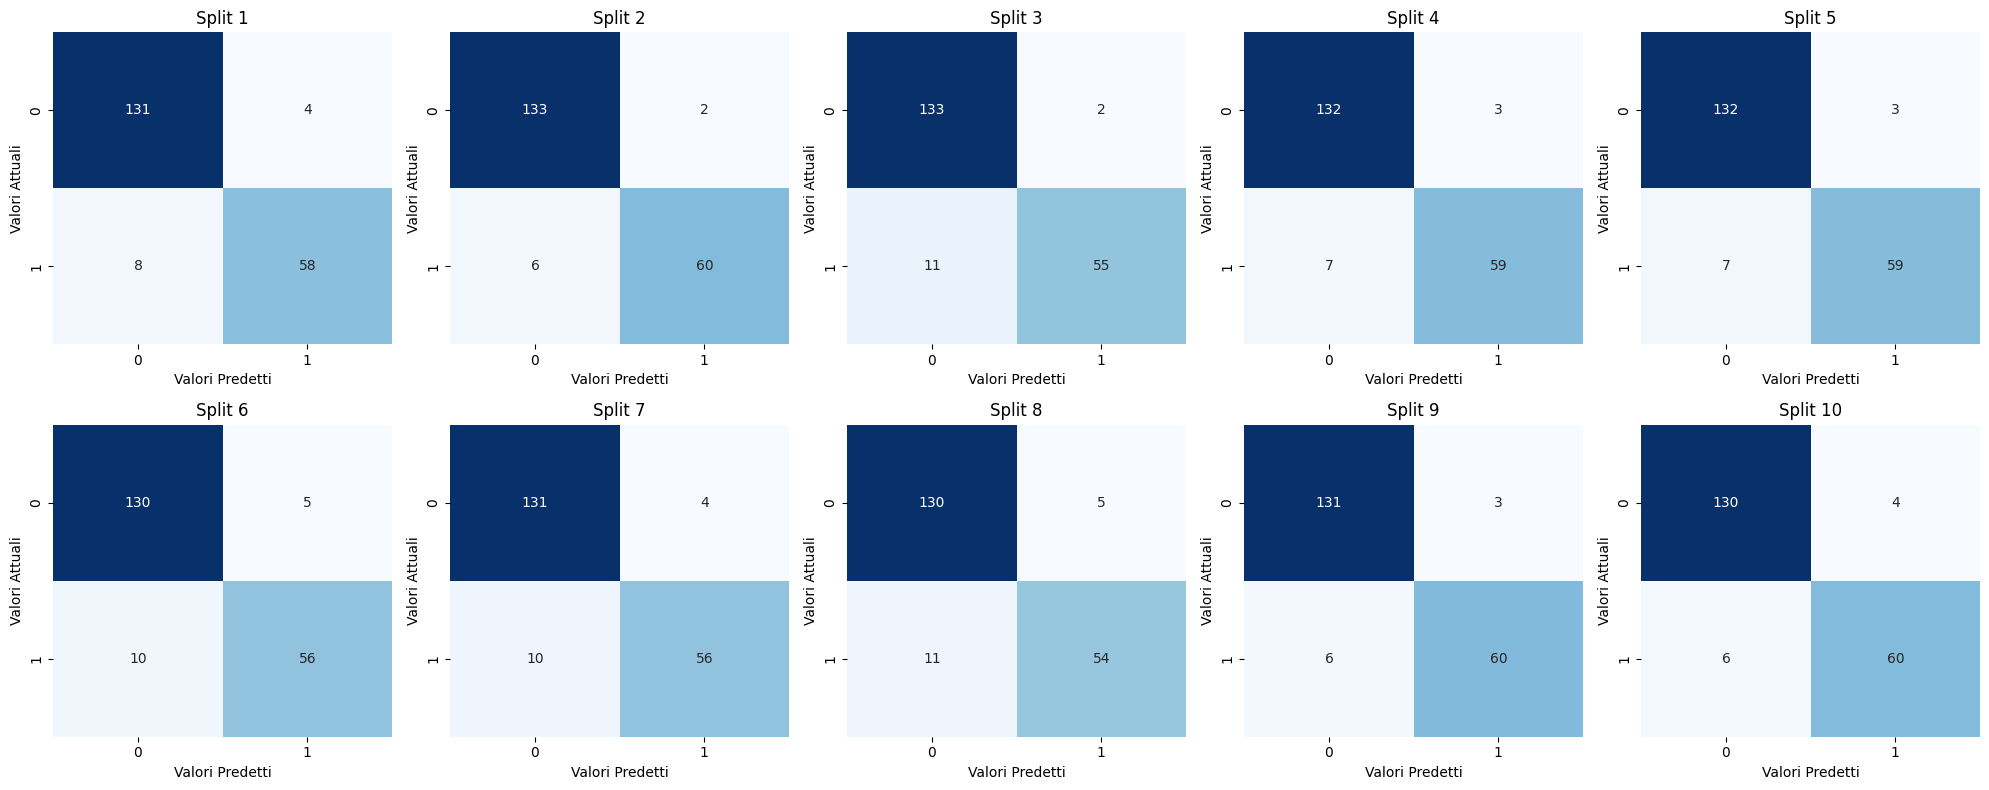

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()

for i, data in enumerate(set_robustezza):
    stacking_classifier.fit(data['X_train'], data['y_train'])

    y_pred = stacking_classifier.predict(data['X_test'])

    cm = confusion_matrix(data['y_test'], y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues',
                ax=axes[i])
    axes[i].set_title(f'Split {i+1}')
    axes[i].set_xlabel('Valori Predetti')
    axes[i].set_ylabel('Valori Attuali')

    sensitivity = recall_score(data['y_test'], y_pred, average='binary')
    print(f"Split {i+1} - Sensitivity: {sensitivity:.3f}")

plt.tight_layout()
plt.show()

Notiamo una cosa: il nostro modello sembra avere più difficoltà a classificare le istanze positive, riducendo quindi la sensitivity/recall.

Verifichiamo se questo è vero anche per il nostro Decision Tree, che era il secondo miglior risultato. Riprendiamo il set “normale”.

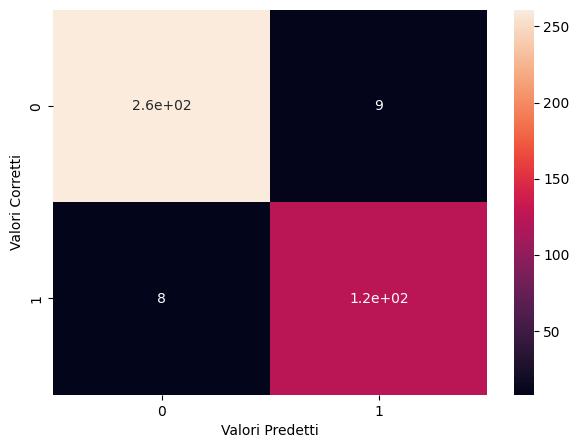

In [ ]:
pred_dt = best_dt.predict(X_test_rilev)
cm_dt = confusion_matrix(y_test_rilev, pred_dt)
plt.figure(figsize=(7,5))
sns.heatmap(cm_dt,annot=True)
plt.xlabel('Valori Predetti')
plt.ylabel('Valori Corretti')
plt.show()

Questa matrice di confusione è la stessa dello Stacking, ma ora verifichiamo se anche il nostro Decision Tree ha questi errori più pendenti verso i falsi negativi.

Split 1 - Sensitivity: 0.879
Split 2 - Sensitivity: 0.909
Split 3 - Sensitivity: 0.833
Split 4 - Sensitivity: 0.924
Split 5 - Sensitivity: 0.879
Split 6 - Sensitivity: 0.848
Split 7 - Sensitivity: 0.848
Split 8 - Sensitivity: 0.831
Split 9 - Sensitivity: 0.909
Split 10 - Sensitivity: 0.924


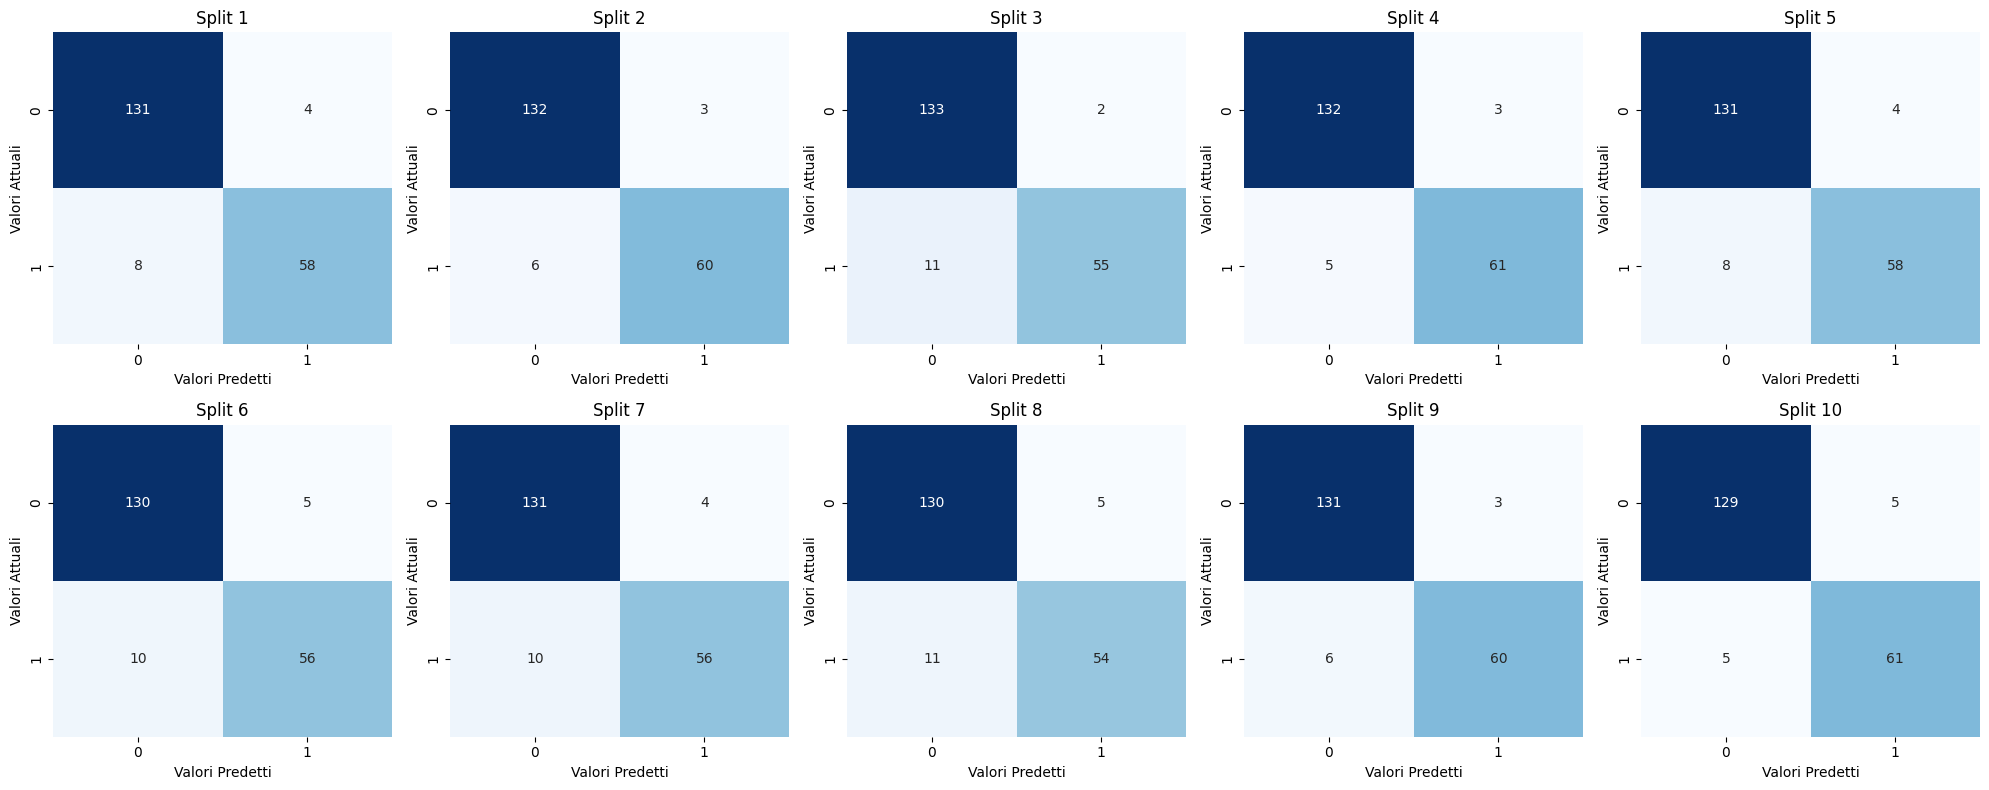

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()

for i, data in enumerate(set_robustezza):
    best_dt.fit(data['X_train'], data['y_train'])

    y_pred = best_dt.predict(data['X_test'])

    cm = confusion_matrix(data['y_test'], y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues',
                ax=axes[i])
    axes[i].set_title(f'Split {i+1}')
    axes[i].set_xlabel('Valori Predetti')
    axes[i].set_ylabel('Valori Attuali')

    sensitivity = recall_score(data['y_test'], y_pred, average='binary')
    print(f"Split {i+1} - Sensitivity: {sensitivity:.3f}")

plt.tight_layout()
plt.show()

Anche Decision Tree ci porta a questo sbilanciamento: in alcuni split, Stacking è migliore mentre in altri è Decision Tree a vincere ma entrambi sono più propensi ad ottenere falsi negativi che falsi positivi. Questo in realtà è in linea con i dati: abbiamo sì il doppio dei falsi negativi ma abbiamo la metà delle classi positive rispetto a quelle negative.

Vogliamo quindi verificare cosa succede se aggiungiamo class_weight='balanced' per il Decision Tree

In [ ]:
params = {'max_depth': list(range(4,20)), 'max_leaf_nodes': list(range(2, 100)), 'min_samples_split': [2, 3, 4]}
balanced_dt = GridSearchCV(DecisionTreeClassifier(random_state=RS, class_weight='balanced'), params, verbose=1, cv=3)

balanced_dt.fit(X_train_rilev, y_train_rilev)

y_pred = balanced_dt.predict(X_test_rilev)
grid_score_balanced_dt = accuracy_score(y_test_rilev, y_pred)
print(grid_score_balanced_dt)
print(balanced_dt.best_params_)
balanced_found_dt = balanced_dt.best_estimator_

Fitting 3 folds for each of 4704 candidates, totalling 14112 fits
0.945273631840796
{'max_depth': 8, 'max_leaf_nodes': 21, 'min_samples_split': 2}


Verifichiamo accuracy come sempre e le matrici di confusione come sopra

Split 1: Test Accuracy = 0.915
Split 2: Test Accuracy = 0.955
Split 3: Test Accuracy = 0.930
Split 4: Test Accuracy = 0.955
Split 5: Test Accuracy = 0.935
Split 6: Test Accuracy = 0.915
Split 7: Test Accuracy = 0.915
Split 8: Test Accuracy = 0.905
Split 9: Test Accuracy = 0.945
Split 10: Test Accuracy = 0.940


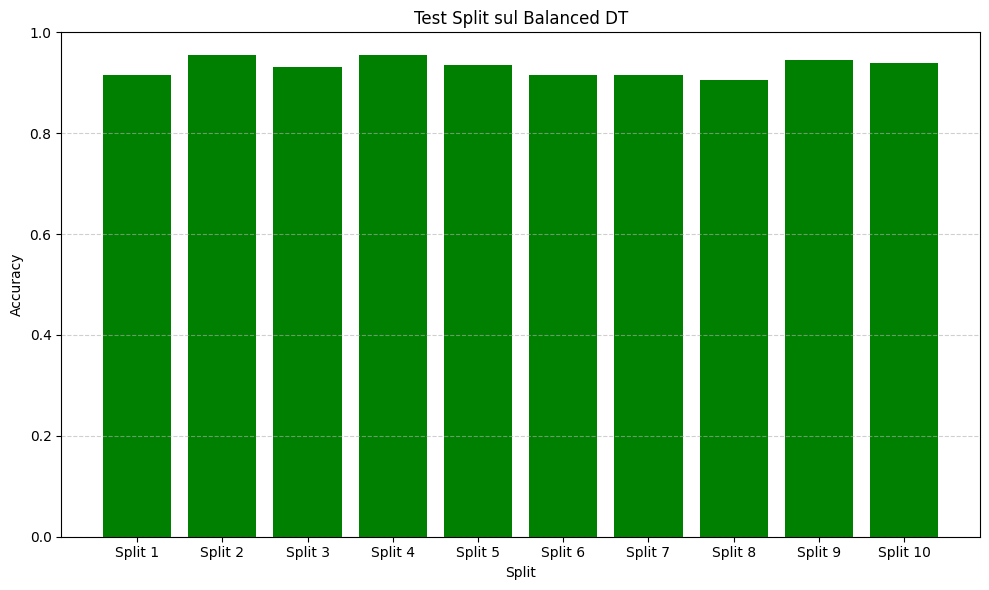

0.9312388059701492
Deviazione Standard delle Accuracy:
0.016950157489382726


np.float64(0.9312388059701492)

In [ ]:
evaluate_model_on_splits(balanced_found_dt, set_robustezza, "Test Split sul Balanced DT")

L'accuracy è calata a 0.931 (da 0.9412) con una deviazione standard di 0.017 (da 0.013)

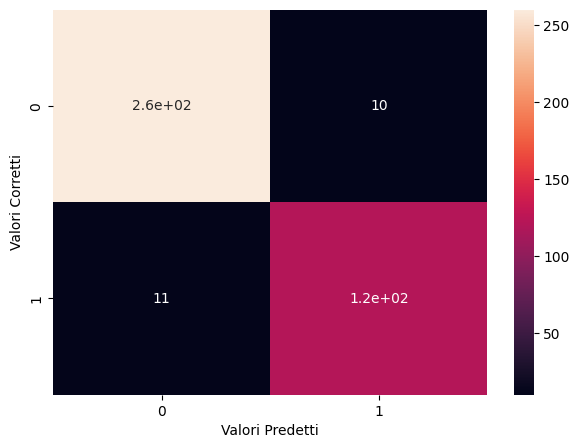

In [ ]:
pred_dt = balanced_found_dt.predict(X_test_rilev)
cm_balanced_dt = confusion_matrix(y_test_rilev, pred_dt)
plt.figure(figsize=(7,5))
sns.heatmap(cm_balanced_dt,annot=True)
plt.xlabel('Valori Predetti')
plt.ylabel('Valori Corretti')
plt.show()

Anche la matrice di confusione segna dei peggioramenti visto che l'error rate è aumentato

Split 1 - Sensitivity: 0.879
Split 2 - Sensitivity: 0.909
Split 3 - Sensitivity: 0.833
Split 4 - Sensitivity: 0.924
Split 5 - Sensitivity: 0.833
Split 6 - Sensitivity: 0.848
Split 7 - Sensitivity: 0.833
Split 8 - Sensitivity: 0.815
Split 9 - Sensitivity: 0.909
Split 10 - Sensitivity: 0.894


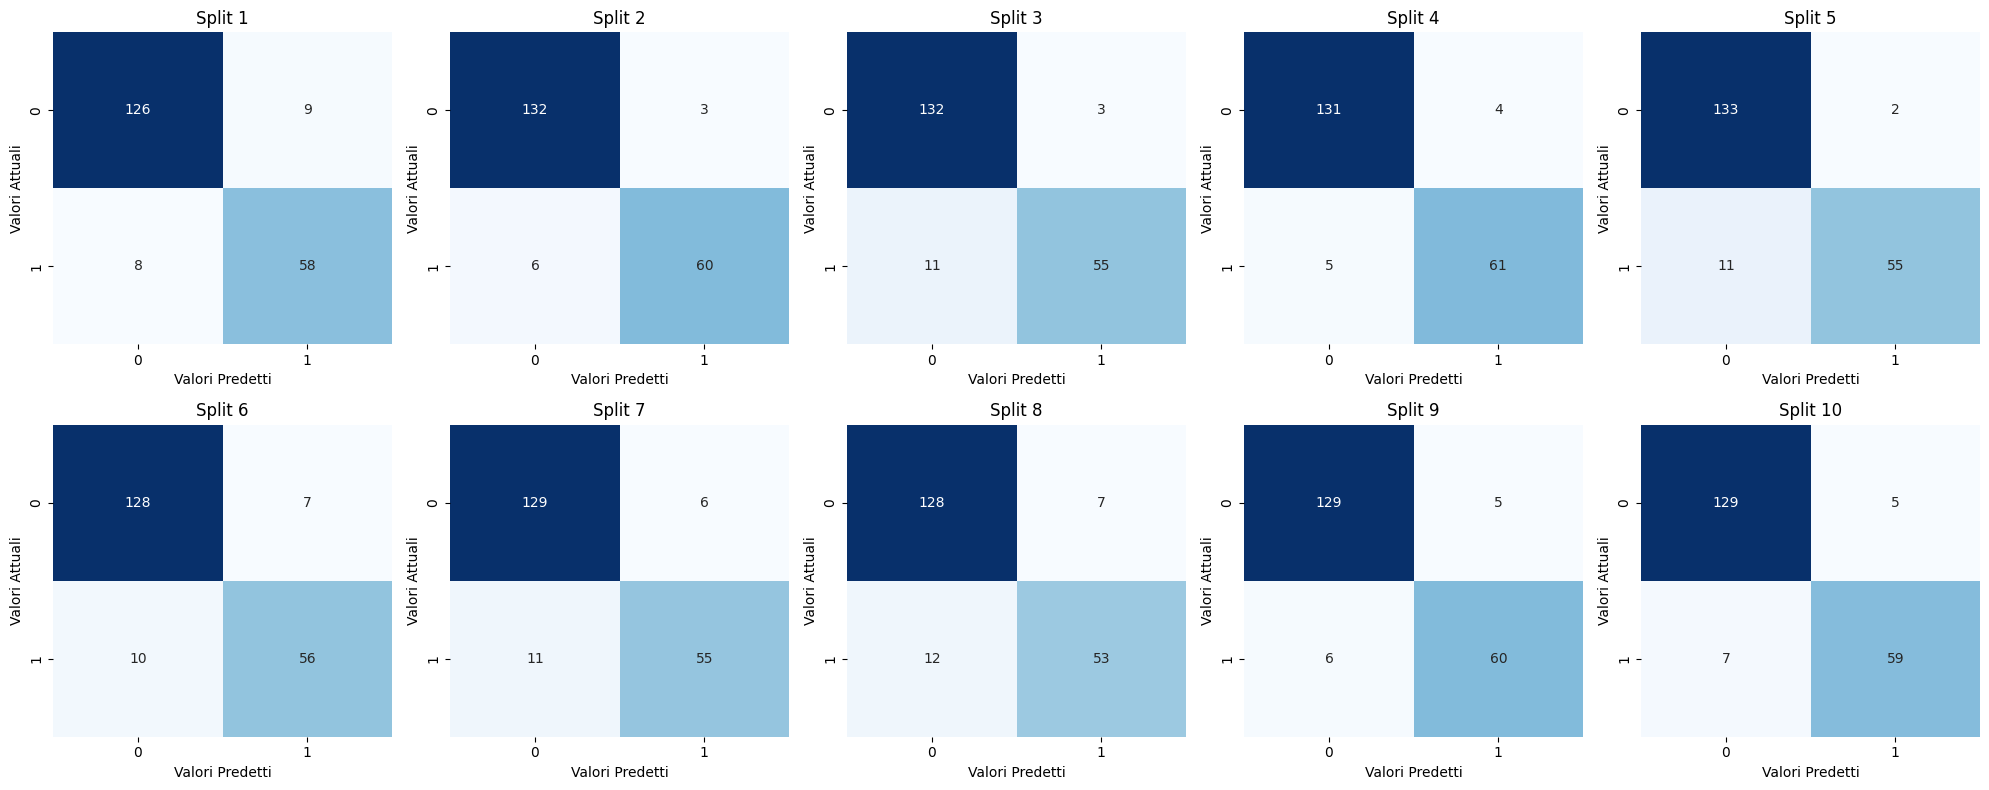

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()

for i, data in enumerate(set_robustezza):
    balanced_found_dt.fit(data['X_train'], data['y_train'])

    y_pred = balanced_found_dt.predict(data['X_test'])

    cm = confusion_matrix(data['y_test'], y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues',
                ax=axes[i])
    axes[i].set_title(f'Split {i+1}')
    axes[i].set_xlabel('Valori Predetti')
    axes[i].set_ylabel('Valori Attuali')

    sensitivity = recall_score(data['y_test'], y_pred, average='binary')
    print(f"Split {i+1} - Sensitivity: {sensitivity:.3f}")

plt.tight_layout()
plt.show()

Eccezione fatta per alcuni split, ora le nostre predizioni sono più bilanciate: abbiamo sacrificato l'accuracy del Decision Tree per ottenere dei risultati finali più bilanciati.

Per stacking, dobbiamo ritrovare il miglior Bagging e la miglior Random Forest (quest'ultima con class_weight='balanced')

In [ ]:
bagging_balanced_dt_grid = BaggingClassifier(
    balanced_found_dt,
    random_state=RS,
    bootstrap=True, oob_score=True
)

param_grid = {
    'n_estimators': [250, 500, 1000, 2000, 3000]
}

bagging_balanced_dt_grid = GridSearchCV(bagging_balanced_dt_grid, param_grid, cv=5, n_jobs=-1)
bagging_balanced_dt_grid.fit(X_train_rilev, y_train_rilev)
grid_bagging_balanced_dt_score = bagging_balanced_dt_grid.score(X_test_rilev, y_test_rilev)
print('Migliori parametri: ', bagging_balanced_dt_grid.best_params_)
print('Score su test: ', grid_bagging_balanced_dt_score)
best_bagging_found_dt = bagging_balanced_dt_grid.best_estimator_

Migliori parametri:  {'n_estimators': 1000}
Score su test:  0.945273631840796


In [ ]:
params = {'n_estimators': [50, 100, 150, 200]}
balaced_rf = GridSearchCV(RandomForestClassifier(random_state=RS, class_weight='balanced'), params, verbose=1, cv=3)

balaced_rf.fit(X_train_rilev, y_train_rilev)
y_balaced_rf = balaced_rf.predict(X_test_rilev)
rf_grid_score = accuracy_score(y_test_rilev, y_balaced_rf)
print(rf_grid_score)
print(balaced_rf.best_params_)
best_balanced_rf = balaced_rf.best_estimator_

Fitting 3 folds for each of 4 candidates, totalling 12 fits
0.9378109452736318
{'n_estimators': 100}


Notare come il miglior numero di stimatori sia cambiato, da 150 a 100

Split 1: Test Accuracy = 0.935
Split 2: Test Accuracy = 0.950
Split 3: Test Accuracy = 0.925
Split 4: Test Accuracy = 0.940
Split 5: Test Accuracy = 0.935
Split 6: Test Accuracy = 0.910
Split 7: Test Accuracy = 0.910
Split 8: Test Accuracy = 0.910
Split 9: Test Accuracy = 0.955
Split 10: Test Accuracy = 0.950


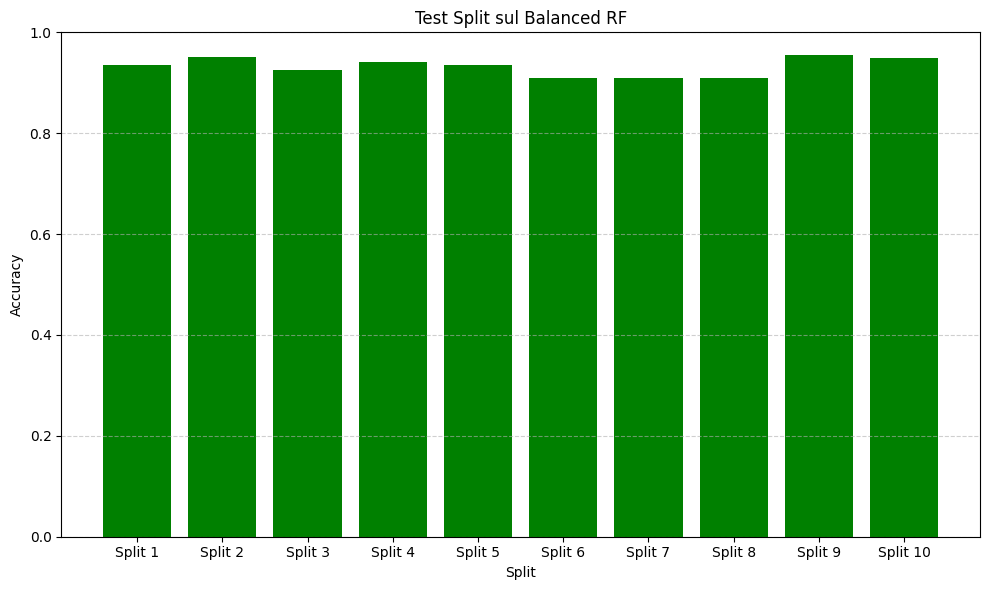

0.9322462686567163
Deviazione Standard delle Accuracy:
0.016532631191420552


np.float64(0.9322462686567163)

In [ ]:
evaluate_model_on_splits(best_balanced_rf, set_robustezza, "Test Split sul Balanced RF")

Notiamo un peggioramento anche per la Random Forest sia in termini di accuracy che di deviazione standard.

In [ ]:
base_learners = [
    ('dt', balanced_found_dt),
    ('rf', best_balanced_rf),
    ('bagDt', best_bagging_found_dt)
]

meta_learner = LogisticRegression(random_state=RS, max_iter=100_000)

stacking_balanced = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=5, n_jobs=-1
)

stacking_balanced.fit(X_train_scaled, y_train_rilev)
balanced_stacking_pred = stacking_balanced.predict(X_test_scaled)
balanced_stacking_score = accuracy_score(y_test_rilev, balanced_stacking_pred)
print(balanced_stacking_score)


0.9477611940298507


Split 1: Test Accuracy = 0.935
Split 2: Test Accuracy = 0.960
Split 3: Test Accuracy = 0.935
Split 4: Test Accuracy = 0.950
Split 5: Test Accuracy = 0.935
Split 6: Test Accuracy = 0.925
Split 7: Test Accuracy = 0.910
Split 8: Test Accuracy = 0.910
Split 9: Test Accuracy = 0.955
Split 10: Test Accuracy = 0.955


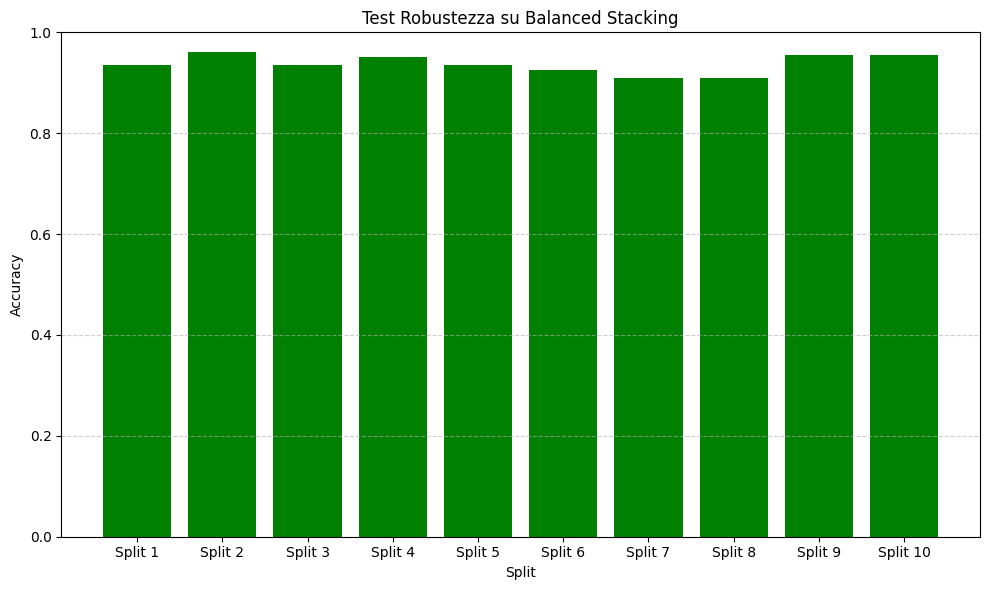

0.9372238805970149
Deviazione Standard delle Accuracy:
0.017143105528945293


np.float64(0.9372238805970149)

In [ ]:
evaluate_model_on_splits(stacking_balanced, set_robustezza, "Test Robustezza su Balanced Stacking")

Notiamo anche qui il peggioramento: siamo passati da 0.9417 a 0.937 con una deviazione standard di 0.017.  
Verifichiamo ora le matrici di confusione.

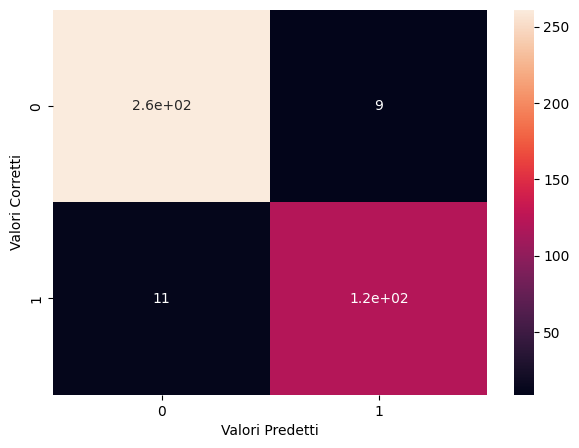

In [ ]:
pred_stacking_balanced = stacking_balanced.predict(X_test_rilev)
cm_balanced_stacking = confusion_matrix(y_test_rilev, pred_stacking_balanced)
plt.figure(figsize=(7,5))
sns.heatmap(cm_balanced_stacking,annot=True)
plt.xlabel('Valori Predetti')
plt.ylabel('Valori Corretti')
plt.show()

Split 1 - Sensitivity: 0.864
Split 2 - Sensitivity: 0.909
Split 3 - Sensitivity: 0.833
Split 4 - Sensitivity: 0.894
Split 5 - Sensitivity: 0.833
Split 6 - Sensitivity: 0.848
Split 7 - Sensitivity: 0.788
Split 8 - Sensitivity: 0.800
Split 9 - Sensitivity: 0.909
Split 10 - Sensitivity: 0.894


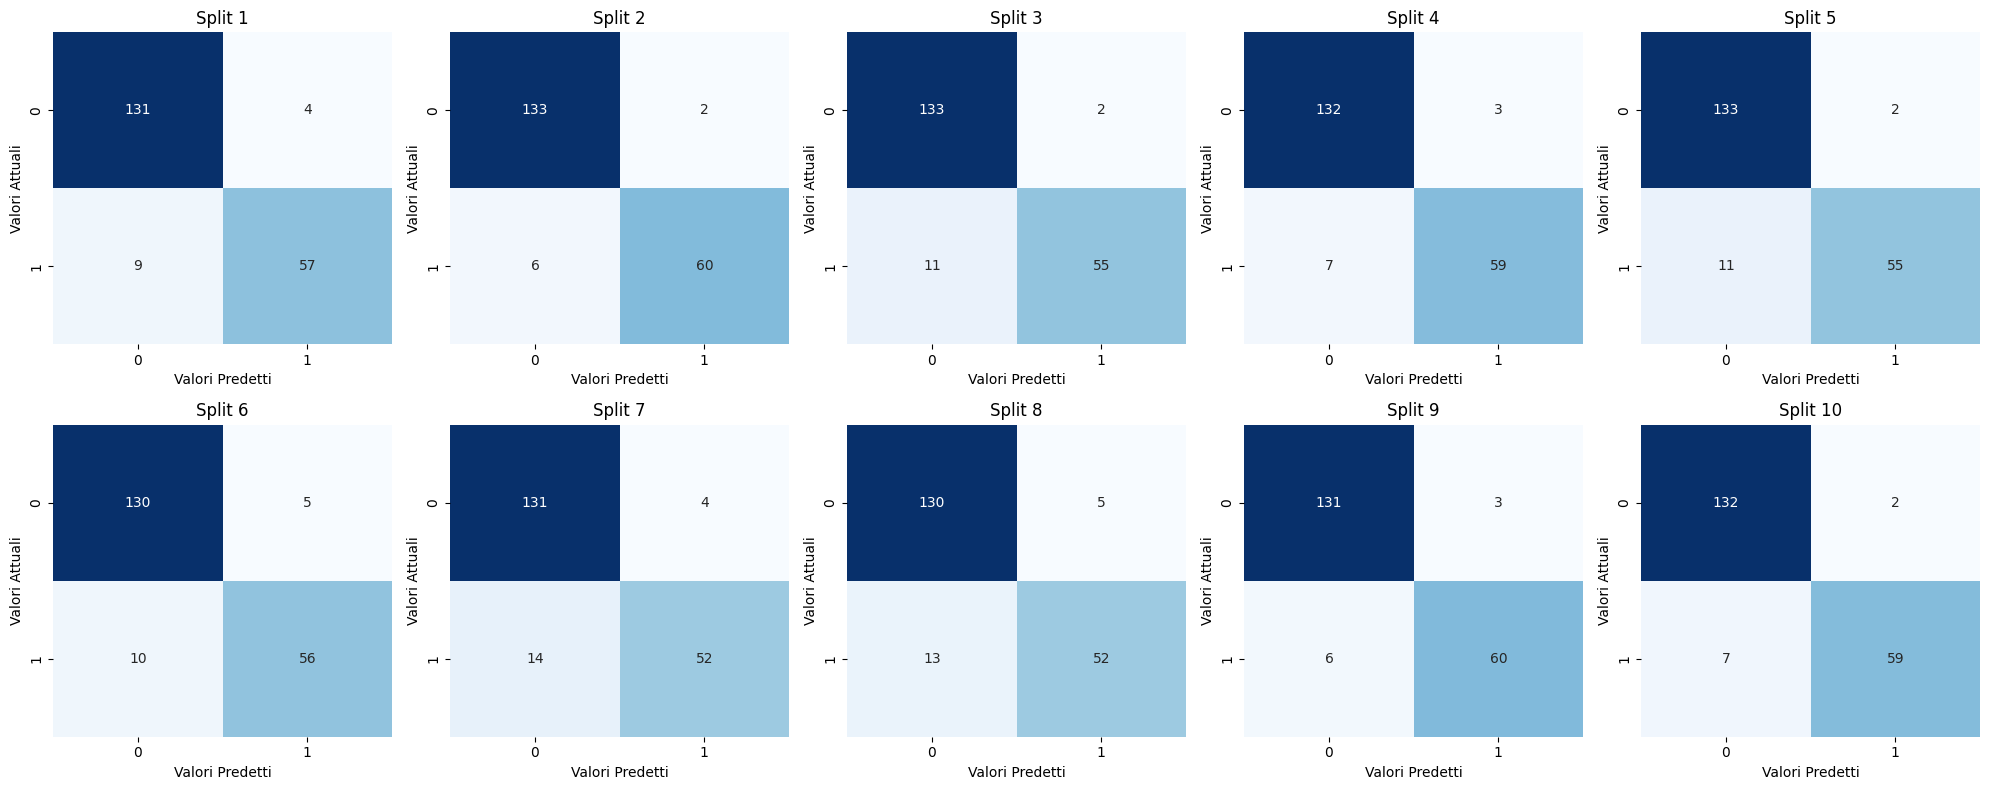

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()

for i, data in enumerate(set_robustezza):
    stacking_balanced.fit(data['X_train'], data['y_train'])

    y_pred = stacking_balanced.predict(data['X_test'])

    cm = confusion_matrix(data['y_test'], y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues',
                ax=axes[i])
    axes[i].set_title(f'Split {i+1}')
    axes[i].set_xlabel('Valori Predetti')
    axes[i].set_ylabel('Valori Attuali')

    sensitivity = recall_score(data['y_test'], y_pred, average='binary')
    print(f"Split {i+1} - Sensitivity: {sensitivity:.3f}")

plt.tight_layout()
plt.show()